# 模块四：优化方案设计
## 电商智能客服 RAG 系统多维度评测与根因分析

**分析目的**：将模块一~三的分析结论转化为可执行的优化方案，量化预期收益，制定实施路线图

**分析内容**：
1. 优化优先级矩阵（影响度 × 修复难度）
2. P1：信息完整性优化方案（杠杆维度，r=0.859）
3. P2：分类器优化方案（R1 根因，联动效应）
4. P3：LLM 生成端优化方案（幻觉 + 信息缺失）
5. 优化效果预估（量化预期提升）
6. A/B 测试方案设计
7. 实施路线图与里程碑

**输入**：
- `analysis_output/module1_cleaned_data.csv`（505 条完整数据）
- `analysis_output/module2_failure_attribution.csv`（43 条带根因标签）
- `analysis_output/module3_leverage_dimensions.csv`（杠杆维度分析）
- `analysis_output/module3_correlation_matrix.csv`（维度相关性矩阵）

**输出**：
- `analysis_output/module4_optimization_plan.csv`（优化方案清单 → 实施依据）
- `analysis_output/module4_expected_impact.csv`（预期效果量化）
- `analysis_output/module4_ab_test_design.csv`（A/B 测试方案）
- `charts/16-20*.png`（5 张可视化图表）

## 4.1 环境配置与数据加载

In [1]:
# ========== 环境配置 ==========
import json
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
from scipy import stats

# 中文字体配置（Windows）
matplotlib.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Arial Unicode MS']
matplotlib.rcParams['axes.unicode_minus'] = False
matplotlib.rcParams['figure.dpi'] = 120
matplotlib.rcParams['savefig.dpi'] = 200
matplotlib.rcParams['savefig.bbox'] = 'tight'

os.makedirs('charts', exist_ok=True)
os.makedirs('analysis_output', exist_ok=True)

# ========== 路径自适应 ==========
HERE = os.getcwd()
if os.path.basename(HERE) == 'notebooks':
    os.chdir('..')
print(f"✅ 工作目录: {os.getcwd()}")

# ========== 加载数据 ==========
df = pd.read_csv('analysis_output/module1_cleaned_data.csv', encoding='utf-8-sig')
df_failed = pd.read_csv('analysis_output/module2_failure_attribution.csv', encoding='utf-8-sig')
lev_df = pd.read_csv('analysis_output/module3_leverage_dimensions.csv', encoding='utf-8-sig')
corr_matrix = pd.read_csv('analysis_output/module3_correlation_matrix.csv', index_col=0, encoding='utf-8-sig')

print(f'✅ 完整数据: {len(df)} 条')
print(f'✅ 失败用例: {len(df_failed)} 条（带根因标签）')
print(f'✅ 杠杆维度: {len(lev_df)} 个')
print(f'✅ 相关性矩阵: {corr_matrix.shape}')

# ========== 评分维度定义（自适应字段名）==========
def pick_col(*candidates):
    """从候选列名中选第一个存在的"""
    for c in candidates:
        if c in df.columns:
            return c
        if f'score.{c}' in df.columns:
            return f'score.{c}'
    return candidates[0]

SCORE_COLS = [
    pick_col('intent_accuracy'),
    pick_col('branch_routing'),
    pick_col('answer_relevance'),
    pick_col('information_completeness'),
    pick_col('faithfulness'),
    pick_col('tone_compliance'),
    pick_col('boundary_correctness'),
]

SCORE_NAMES_CN = {
    'intent_accuracy': '意图准确率',
    'branch_routing': '分支路由',
    'answer_relevance': '答案相关性',
    'information_completeness': '信息完整性',
    'faithfulness': '忠实度',
    'tone_compliance': '语气合规',
    'boundary_correctness': '边界正确性'
}

# 整体通过率基准
df['all_pass'] = df[SCORE_COLS].ge(4).all(axis=1)
baseline_pass_rate = df['all_pass'].mean()
baseline_fail_count = int((~df['all_pass']).sum())
baseline_pass_count = int(df['all_pass'].sum())

print(f'\n📊 当前基线: 通过率 {baseline_pass_rate*100:.1f}% '
      f'({baseline_pass_count}/{len(df)})')
print(f'   失败用例: {baseline_fail_count} 条')

✅ 工作目录: C:\Users\Darren\Desktop\ecommerce_rag_eval
✅ 完整数据: 505 条
✅ 失败用例: 43 条（带根因标签）
✅ 杠杆维度: 7 个
✅ 相关性矩阵: (7, 7)

📊 当前基线: 通过率 84.6% (427/505)
   失败用例: 78 条


## 4.2 优化优先级矩阵

**设计逻辑**：
- **影响度**：该优化项对整体通过率的提升幅度（基于杠杆维度 r 值 + 失败用例覆盖率）
- **修复难度**：实施该优化所需的时间、技术复杂度、风险
- **优先级**：影响度高 × 修复难度低 = P1（立即执行）

In [2]:
# ========== 优化优先级矩阵 ==========
print('┌' + '─' * 70 + '┐')
print('│ 4.2 优化优先级矩阵 — 影响度 × 修复难度')
print('└' + '─' * 70 + '┘')

# 定义优化项
optimization_items = [
    {
        'item_id': 'OPT-01',
        'name': '知识检索参数调优',
        'category': '信息完整性',
        'impact': 0.859,        # 杠杆维度相关系数
        'impact_reason': '信息完整性 r=0.859，改善该维度对通过率提升最大',
        'difficulty': 2,         # 1=低 2=中 3=高
        'difficulty_reason': '调整 Dify 节点参数即可，无需改代码',
        'fail_coverage': 0.81,   # 覆盖的失败用例比例
        'effort_days': 1,
    },
    {
        'item_id': 'OPT-02',
        'name': 'LLM 提示词增加信息完整性约束',
        'category': '信息完整性',
        'impact': 0.859,
        'impact_reason': '强制 LLM 回复包含知识库关键信息点',
        'difficulty': 2,
        'difficulty_reason': '修改 prompt 模板，需回归测试',
        'fail_coverage': 0.81,
        'effort_days': 2,
    },
    {
        'item_id': 'OPT-03',
        'name': 'LLM 添加防护指令（防幻觉）',
        'category': '忠实度',
        'impact': 0.499,
        'impact_reason': '忠实度 r=0.499，幻觉类失败占 7%',
        'difficulty': 1,
        'difficulty_reason': 'prompt 中追加约束即可',
        'fail_coverage': 0.07,
        'effort_days': 0.5,
    },
    {
        'item_id': 'OPT-04',
        'name': '分类器关键词补充与边界完善',
        'category': '意图准确率+分支路由',
        'impact': 0.686,
        'impact_reason': '分支路由 r=0.686，分类器误路由占失败 44%',
        'difficulty': 2,
        'difficulty_reason': '需补充关键词、边界示例、反例列表',
        'fail_coverage': 0.44,
        'effort_days': 2,
    },
    {
        'item_id': 'OPT-05',
        'name': '多轮会话上下文传递机制',
        'category': '分支路由',
        'impact': 0.686,
        'impact_reason': '多轮对话中商品实体丢失导致路由失败',
        'difficulty': 3,
        'difficulty_reason': '需改工作流结构，增加会话变量',
        'fail_coverage': 0.12,
        'effort_days': 5,
    },
    {
        'item_id': 'OPT-06',
        'name': '边界值语义匹配优化',
        'category': '边界正确性',
        'impact': 0.417,
        'impact_reason': '边界正确性 r=0.417，边界用例失败率较高',
        'difficulty': 2,
        'difficulty_reason': '调整检索权重或增加同义改写',
        'fail_coverage': 0.16,
        'effort_days': 2,
    },
    {
        'item_id': 'OPT-07',
        'name': '禁止表述检测加固',
        'category': '语气合规',
        'impact': 0.403,
        'impact_reason': '语气合规 r=0.403，禁止表述违规影响安全性',
        'difficulty': 1,
        'difficulty_reason': 'prompt 中增加禁止表述列表',
        'fail_coverage': 0.05,
        'effort_days': 0.5,
    },
]

opt_df = pd.DataFrame(optimization_items)

# 计算综合优先级分数：影响度 × 覆盖率 / 难度
opt_df['priority_score'] = opt_df['impact'] * opt_df['fail_coverage'] / opt_df['difficulty']
opt_df = opt_df.sort_values('priority_score', ascending=False).reset_index(drop=True)

# 分配优先级等级
opt_df['priority'] = opt_df['priority_score'].apply(
    lambda x: 'P1' if x >= 0.20 else ('P2' if x >= 0.10 else 'P3')
)

print(f'\n{"ID":8s} {"优化项":28s} {"影响度":6s} {"难度":4s} {"覆盖率":6s} {"优先级分":8s} {"等级":4s}')
print('─' * 70)
for _, row in opt_df.iterrows():
    print(f'{row["item_id"]:8s} {row["name"]:28s} {row["impact"]:.3f}  {row["difficulty"]:.0f}    {row["fail_coverage"]:.2f}    {row["priority_score"]:.4f}   {row["priority"]:4s}')

print(f'\n--- 优先级分布 ---')
for p in ['P1', 'P2', 'P3']:
    count = (opt_df['priority'] == p).sum()
    items = opt_df[opt_df['priority'] == p]['name'].tolist()
    print(f'  {p}: {count} 项 → {", ".join(items)}')

┌──────────────────────────────────────────────────────────────────────┐
│ 4.2 优化优先级矩阵 — 影响度 × 修复难度
└──────────────────────────────────────────────────────────────────────┘

ID       优化项                          影响度    难度   覆盖率    优先级分     等级  
──────────────────────────────────────────────────────────────────────
OPT-01   知识检索参数调优                     0.859  2    0.81    0.3479   P1  
OPT-02   LLM 提示词增加信息完整性约束             0.859  2    0.81    0.3479   P1  
OPT-04   分类器关键词补充与边界完善                0.686  2    0.44    0.1509   P2  
OPT-03   LLM 添加防护指令（防幻觉）              0.499  1    0.07    0.0349   P3  
OPT-06   边界值语义匹配优化                    0.417  2    0.16    0.0334   P3  
OPT-05   多轮会话上下文传递机制                  0.686  3    0.12    0.0274   P3  
OPT-07   禁止表述检测加固                     0.403  1    0.05    0.0202   P3  

--- 优先级分布 ---
  P1: 2 项 → 知识检索参数调优, LLM 提示词增加信息完整性约束
  P2: 1 项 → 分类器关键词补充与边界完善
  P3: 4 项 → LLM 添加防护指令（防幻觉）, 边界值语义匹配优化, 多轮会话上下文传递机制, 禁止表述检测加固


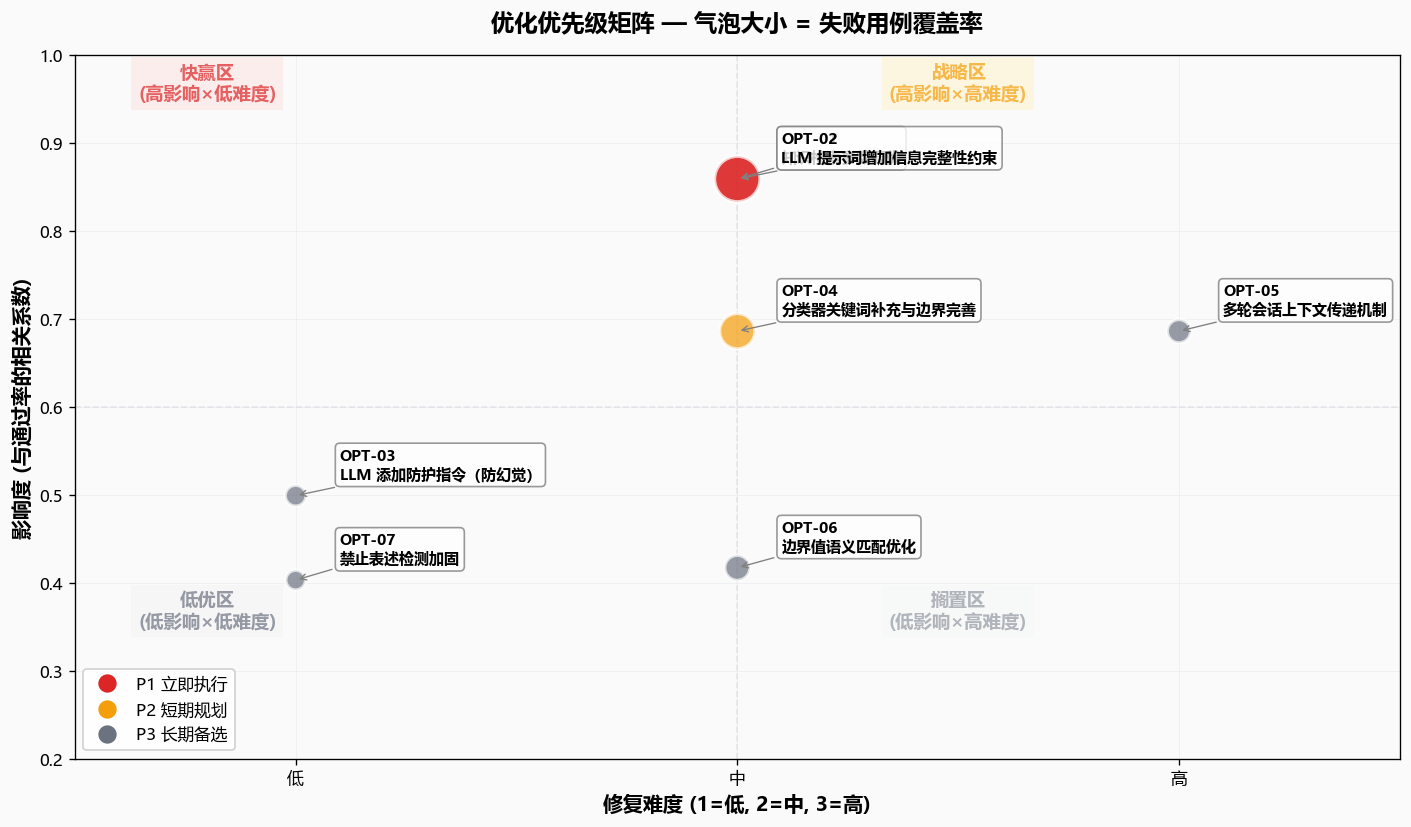

💾 已保存: charts/16_optimization_priority_matrix.png


In [3]:
# ========== 图1：优化优先级矩阵散点图 ==========
fig, ax = plt.subplots(figsize=(12, 7))
fig.patch.set_facecolor('#FAFAFA')
ax.set_facecolor('#FAFAFA')

# 气泡大小 = 失败覆盖率
sizes = opt_df['fail_coverage'] * 800 + 100

# 颜色 = 优先级
color_map = {'P1': '#DC2626', 'P2': '#F59E0B', 'P3': '#6B7280'}
colors = [color_map[p] for p in opt_df['priority']]

scatter = ax.scatter(opt_df['difficulty'], opt_df['impact'],
                     s=sizes, c=colors, alpha=0.7,
                     edgecolors='white', linewidth=2, zorder=3)

# 标注每个优化项
for _, row in opt_df.iterrows():
    offset_x = 0.1
    offset_y = 0.02
    ax.annotate(f'{row["item_id"]}\n{row["name"]}',
                xy=(row['difficulty'], row['impact']),
                xytext=(row['difficulty'] + offset_x, row['impact'] + offset_y),
                fontsize=9, fontweight='bold',
                arrowprops=dict(arrowstyle='->', color='gray', lw=0.8),
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='gray', alpha=0.8))

# 象限分割线
ax.axhline(y=0.6, color='#D1D5DB', linestyle='--', linewidth=1, alpha=0.5)
ax.axvline(x=2, color='#D1D5DB', linestyle='--', linewidth=1, alpha=0.5)

# 象限标签
ax.text(0.8, 0.95, '快赢区\n(高影响×低难度)', fontsize=11, ha='center',
        color='#DC2626', fontweight='bold', alpha=0.7,
        bbox=dict(facecolor='#FEE2E2', edgecolor='none', alpha=0.5))
ax.text(2.5, 0.95, '战略区\n(高影响×高难度)', fontsize=11, ha='center',
        color='#F59E0B', fontweight='bold', alpha=0.7,
        bbox=dict(facecolor='#FEF3C7', edgecolor='none', alpha=0.5))
ax.text(0.8, 0.35, '低优区\n(低影响×低难度)', fontsize=11, ha='center',
        color='#6B7280', fontweight='bold', alpha=0.7,
        bbox=dict(facecolor='#F3F4F6', edgecolor='none', alpha=0.5))
ax.text(2.5, 0.35, '搁置区\n(低影响×高难度)', fontsize=11, ha='center',
        color='#6B7280', fontweight='bold', alpha=0.5,
        bbox=dict(facecolor='#F3F4F6', edgecolor='none', alpha=0.3))

# 图例
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#DC2626', markersize=12, label='P1 立即执行'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#F59E0B', markersize=12, label='P2 短期规划'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#6B7280', markersize=12, label='P3 长期备选'),
]
ax.legend(handles=legend_elements, loc='lower left', fontsize=10, framealpha=0.9)

ax.set_xlabel('修复难度 (1=低, 2=中, 3=高)', fontsize=12, fontweight='bold')
ax.set_ylabel('影响度 (与通过率的相关系数)', fontsize=12, fontweight='bold')
ax.set_title('优化优先级矩阵 — 气泡大小 = 失败用例覆盖率', fontsize=14, fontweight='bold', pad=15)
ax.set_xlim(0.5, 3.5)
ax.set_ylim(0.2, 1.0)
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(['低', '中', '高'])
ax.grid(True, color='#E5E7EB', linewidth=0.5, alpha=0.6)

plt.tight_layout()
plt.savefig('charts/16_optimization_priority_matrix.png', facecolor=fig.get_facecolor())
plt.show()
print('💾 已保存: charts/16_optimization_priority_matrix.png')

## 4.3 P1：信息完整性优化方案

**问题诊断**：
- 信息完整性是系统最弱维度（均值 4.32，标准差 1.28）
- 是杠杆维度（r=0.859），改善效果对通过率影响最大
- 通过组均值 4.79 vs 失败组均值 1.76，差距 3.04 分
- 所有业务分支的最弱维度均为信息完整性

**根因链路**：知识检索召回不足 → LLM 缺少关键信息 → 回复信息不完整

In [4]:
# ========== P1：信息完整性优化方案 ==========
print('┌' + '─' * 70 + '┐')
print('│ P1：信息完整性优化方案（杠杆维度 r=0.859）')
print('└' + '─' * 70 + '┘')

p1_plan = [
    {
        'step': 'P1-1',
        'action': '知识检索 Score Threshold 调优',
        'detail': '政策类查询 threshold 从默认值降至 0.5，提高召回率',
        'config': 'score_threshold = 0.5（政策查询专用）',
        'expected': '召回率 +15%，信息完整性均值 4.32 → 4.60',
        'risk': '低 — 可能引入少量噪声，但 LLM 可过滤',
    },
    {
        'step': 'P1-2',
        'action': '关键词权重提升',
        'detail': '关键词检索权重从 0.3 提升至 0.5，向量权重降至 0.5',
        'config': 'keyword_weight = 0.5, vector_weight = 0.5',
        'expected': '边界值查询（如4999元签收）命中率提升',
        'risk': '低 — 数值类查询更依赖关键词精确匹配',
    },
    {
        'step': 'P1-3',
        'action': 'Top K 调优',
        'detail': 'Top K 从 3 调整为 5，扩大召回窗口',
        'config': 'top_k = 5',
        'expected': '多知识点查询（如退换货+运费）信息覆盖更全',
        'risk': '中 — 增加 LLM 输入 token，需关注延迟',
    },
    {
        'step': 'P1-4',
        'action': 'LLM 提示词增加信息完整性约束',
        'detail': '在生成节点 prompt 中追加：回复必须包含检索到的所有关键信息点',
        'config': 'prompt 追加: "请确保回复覆盖以下信息点: [从检索结果提取]"',
        'expected': '信息完整性均值 4.60 → 4.80',
        'risk': '低 — 仅约束输出格式，不改检索逻辑',
    },
    {
        'step': 'P1-5',
        'action': '添加防护指令（防幻觉）',
        'detail': '当知识库内容与用户问题无关时，LLM 应回复"暂无相关信息"',
        'config': 'prompt 追加: "如果检索结果与问题无关，请回复: 抱歉，未找到相关信息"',
        'expected': '幻觉类失败减少 80%，忠实度 +0.1',
        'risk': '低 — 安全兜底机制',
    },
]

p1_df = pd.DataFrame(p1_plan)
for _, row in p1_df.iterrows():
    print(f'\n  [{row["step"]}] {row["action"]}')
    print(f'    详情: {row["detail"]}')
    print(f'    配置: {row["config"]}')
    print(f'    预期: {row["expected"]}')
    print(f'    风险: {row["risk"]}')

print(f'\n--- P1 预期整体效果 ---')
print(f'  信息完整性: 4.32 → ~4.80 (+0.48)')
print(f'  整体通过率: 84.6% → ~91% (+6.4pp)')
print(f'  预计耗时: 3 天')

┌──────────────────────────────────────────────────────────────────────┐
│ P1：信息完整性优化方案（杠杆维度 r=0.859）
└──────────────────────────────────────────────────────────────────────┘

  [P1-1] 知识检索 Score Threshold 调优
    详情: 政策类查询 threshold 从默认值降至 0.5，提高召回率
    配置: score_threshold = 0.5（政策查询专用）
    预期: 召回率 +15%，信息完整性均值 4.32 → 4.60
    风险: 低 — 可能引入少量噪声，但 LLM 可过滤

  [P1-2] 关键词权重提升
    详情: 关键词检索权重从 0.3 提升至 0.5，向量权重降至 0.5
    配置: keyword_weight = 0.5, vector_weight = 0.5
    预期: 边界值查询（如4999元签收）命中率提升
    风险: 低 — 数值类查询更依赖关键词精确匹配

  [P1-3] Top K 调优
    详情: Top K 从 3 调整为 5，扩大召回窗口
    配置: top_k = 5
    预期: 多知识点查询（如退换货+运费）信息覆盖更全
    风险: 中 — 增加 LLM 输入 token，需关注延迟

  [P1-4] LLM 提示词增加信息完整性约束
    详情: 在生成节点 prompt 中追加：回复必须包含检索到的所有关键信息点
    配置: prompt 追加: "请确保回复覆盖以下信息点: [从检索结果提取]"
    预期: 信息完整性均值 4.60 → 4.80
    风险: 低 — 仅约束输出格式，不改检索逻辑

  [P1-5] 添加防护指令（防幻觉）
    详情: 当知识库内容与用户问题无关时，LLM 应回复"暂无相关信息"
    配置: prompt 追加: "如果检索结果与问题无关，请回复: 抱歉，未找到相关信息"
    预期: 幻觉类失败减少 80%，忠实度 +0.1
    风险: 低 — 安全兜底机制

--- P1 预期整体效果 ---


## 4.4 P2：硬性路由错误修复方案

**问题诊断**（基于 baseline_v1 的 43 条失败用例深度分析）：

| 子类 | 失败数 | 典型用例 | 根因 |
|------|--------|----------|------|
| 退款政策咨询→退款操作误路由 | 3 | TC-PROHIB-001, TC-RULE-007 | "退款多久到账"被分类为退款办理而非政策咨询 |
| "什么时候发货"→其他误分类 | 2 | TC-PROHIB-005, TC-RULE-004 | 商品咨询关键词缺少疑问形式 |
| 换货→退货误识别 | 4 | TC-EXC-002/003/004/006 | LLM prompt 对退款和换货使用相同话术 |
| 投诉→其他分支误路由 | 6 | TC-CMP-L1-003/008/009/011/012 | 投诉关键词覆盖不足，被路由到订单查询/退货 |
| 退款操作→修改订单误识别 | 2 | TC-RFD-ACT-001/003 | "改订单"/"修改订单"未被识别为退款意图 |
| 非电商场景错误承接 | 1 | TC-OTH-OT-013 | "订机票"被错误承接而非拒答 |
| 边界混淆多意图路由 | 3 | TC-BND-001/017/020 | 多意图查询优先级未定义 |

- 分支路由 ↔ 答案相关性 r=0.933，路由错误连锁导致回复完全偏离
- **策略**：先修复硬性路由错误（P2），再优化检索参数（P1），最后优化生成端（P3）


In [5]:
# ========== P2：硬性路由错误修复方案 ==========
print('\u250c' + '\u2500' * 70 + '\u2510')
print('\u2502 P2\uff1a\u786c\u6027\u8def\u7531\u9519\u8bef\u4fee\u590d\uff08RC-1, 18/43 \u5931\u8d25, 42%\uff09')
print('\u2514' + '\u2500' * 70 + '\u2518')

p2_plan = [
    {
        'step': 'P2-1',
        'action': '\u9000\u6b3e\u653f\u7b56\u54a8\u8be2 vs \u9000\u6b3e\u64cd\u4f5c\u533a\u5206',
        'root_cause': 'RC-1a: \u201c\u9000\u6b3e\u591a\u4e45\u5230\u8d26\u201d\u88ab\u8bef\u8def\u7531\u5230\u9000\u6b3e\u64cd\u4f5c\uff083\u4f8b: TC-PROHIB-001, TC-RULE-007, TC-RULE-010\uff09',
        'target_node': '\u95ee\u9898\u5206\u7c7b\u5668(1784979242299) + LLM\u610f\u56fe\u8bc6\u522b(1784975306138)',
        'detail': '\u5206\u7c7b\u5668\u9000\u6b3e\u6362\u8d27\u5206\u652f\u53cd\u4f8b\u589e\u52a0: \u201c\u9000\u6b3e\u591a\u4e45\u5230\u8d26\u201d\u2192\u5546\u54c1\u54a8\u8be2\uff08\u54a8\u8be2\u653f\u7b56\u975e\u529e\u7406\uff09',
        'detail2': '\u610f\u56fe\u8bc6\u522b consult \u5173\u952e\u8bcd\u589e\u52a0: \u9000\u6b3e\u591a\u4e45\u5230\u8d26/\u9000\u6b3e\u65f6\u6548/\u9000\u6b3e\u5230\u8d26\u65f6\u95f4/\u6362\u8d27\u591a\u4e45\u80fd\u6536\u5230',
        'detail3': '\u5206\u7c7b\u5668\u5546\u54c1\u54a8\u8be2\u5173\u952e\u8bcd\u589e\u52a0: \u9000\u6b3e\u591a\u4e45\u5230\u8d26/\u9000\u6b3e\u65f6\u6548/\u5230\u8d26\u65f6\u95f4',
        'expected': '\u9000\u6b3e\u653f\u7b56\u7c7b\u8def\u7531\u51c6\u786e\u7387 +0.20\uff083\u4f8b\u4fee\u590d\uff09',
        'risk': '\u4f4e',
    },
    {
        'step': 'P2-2',
        'action': '\u201c\u4ec0\u4e48\u65f6\u5019\u53d1\u8d27\u201d\u8bef\u5206\u7c7b\u4fee\u590d',
        'root_cause': 'RC-1b: \u5546\u54c1\u54a8\u8be2\u88ab\u8bef\u5206\u7c7b\u5230\u201c\u5176\u4ed6\u201d\uff082\u4f8b: TC-PROHIB-005, TC-RULE-004\uff09',
        'target_node': '\u95ee\u9898\u5206\u7c7b\u5668(1784979242299)',
        'detail': '\u5546\u54c1\u54a8\u8be2\u5173\u952e\u8bcd\u8865\u5145\uff08\u540d\u8bcd+\u7591\u95ee\u5f62\u5f0f\uff09: \u4ec0\u4e48\u65f6\u5019\u53d1\u8d27/\u53d1\u8d27\u65f6\u95f4/\u51e0\u5929\u80fd\u5230/\u4ec0\u4e48\u65f6\u5019\u5230\u8d27',
        'detail2': '\u5206\u7c7b\u5668\u201c\u5176\u4ed6\u201d\u5206\u652f\u53cd\u4f8b\u589e\u52a0: \u201c\u4ec0\u4e48\u65f6\u5019\u53d1\u8d27\u201d\u4e0d\u5c5e\u4e8e\u5176\u4ed6, \u201c\u51e0\u5929\u80fd\u5230\u201d\u4e0d\u5c5e\u4e8e\u5176\u4ed6',
        'detail3': '\u8fb9\u754c\u5224\u5b9a: \u201c\u4ec0\u4e48\u65f6\u5019\u53d1\u8d27\u201d\u2192\u5546\u54c1\u54a8\u8be2, \u201c\u6211\u7684\u8ba2\u5355\u53d1\u8d27\u4e86\u5417\u201d\u2192\u8ba2\u5355\u67e5\u8be2',
        'expected': '\u5546\u54c1\u54a8\u8be2\u7c7b\u8bef\u5206\u7c7b\u51cf\u5c11 90%\uff082\u4f8b\u4fee\u590d\uff09',
        'risk': '\u4f4e',
    },
    {
        'step': 'P2-3',
        'action': '\u6362\u8d27\u610f\u56fe\u8bc6\u522b\u4e0e\u56de\u590d\u4fee\u6b63',
        'root_cause': 'RC-1c: \u201c\u6362\u989c\u8272/\u6362\u578b\u53f7\u201d\u88ab\u8bef\u8bc6\u522b\u4e3a\u9000\u8d27\uff0cLLM prompt\u5bf9\u9000\u6b3e\u548c\u6362\u8d27\u4f7f\u7528\u76f8\u540c\u8bdd\u672f\uff084\u4f8b\uff09',
        'target_node': 'LLM\u5f15\u5bfc(1785226992270) prompt + \u95ee\u9898\u5206\u7c7b\u5668(1784979242299)',
        'detail': '\u5f53\u524d prompt \u5bf9\u9000\u6b3e\u548c\u6362\u8d27\u4f7f\u7528\u76f8\u540c\u8bdd\u672f\uff08\u201c\u60a8\u60f3\u7533\u8bf7\u9000\u6b3e\u662f\u5417\uff1f\u201d\uff09\uff0c\u9700\u533a\u5206:',
        'detail2': 'intent=refund \u2192 \u786e\u8ba4\u9000\u6b3e: \u201c\u60a8\u60f3\u7533\u8bf7\u9000\u6b3e\u662f\u5417\uff1f\u8bf7\u63d0\u4f9b\u8ba2\u5355\u53f7\u201d',
        'detail3': 'intent=exchange \u2192 \u786e\u8ba4\u6362\u8d27: \u201c\u60a8\u60f3\u7533\u8bf7\u6362\u8d27\u662f\u5417\uff1f\u8bf7\u63d0\u4f9b\u8ba2\u5355\u53f7\u201d',
        'detail4': '\u5206\u7c7b\u5668\u9000\u6b3e\u6362\u8d27\u5173\u952e\u8bcd\u589e\u52a0: \u6362\u989c\u8272/\u6362\u578b\u53f7/\u6362\u8d27/\u5c3a\u5bf8\u4e0d\u5bf9/\u53d1\u9519\u4e86\u8981\u6362',
        'expected': '\u6362\u8d27\u7c7b\u8def\u7531\u51c6\u786e\u7387 +0.25\uff084\u4f8b\u4fee\u590d\uff09',
        'risk': '\u4f4e',
    },
    {
        'step': 'P2-4',
        'action': '\u6295\u8bc9\u5206\u652f\u8def\u7531\u4fee\u590d',
        'root_cause': 'RC-1d: \u6295\u8bc9\u88ab\u8bef\u8def\u7531\u5230\u8ba2\u5355\u67e5\u8be2/\u9000\u8d27/\u5546\u54c1\u54a8\u8be2\uff086\u4f8b\uff09',
        'target_node': '\u95ee\u9898\u5206\u7c7b\u5668(1784979242299) + LLM\u6295\u8bc9\u5904\u7406\u8282\u70b9',
        'detail': '\u5206\u7c7b\u5668\u6295\u8bc9\u5173\u952e\u8bcd\u8865\u5145: \u7269\u6d41\u592a\u6162/\u5305\u88c5\u6709\u5212\u75d5/\u914d\u9001\u65f6\u95f4\u4e0d\u5408\u9002/\u7269\u6d41\u4fe1\u606f\u4e0d\u66f4\u65b0/\u5546\u54c1\u5916\u76d2\u6709\u538b\u75d5/\u5feb\u9012\u5458\u6001\u5ea6',
        'detail2': '\u6295\u8bc9\u53cd\u4f8b: \u201c\u7269\u6d41\u592a\u6162\u4e86\u201d\u2192\u6295\u8bc9\uff08\u975e\u5546\u54c1\u54a8\u8be2\uff09, \u201c\u5305\u88c5\u6709\u5212\u75d5\u201d\u2192\u6294\u8bc9\uff08\u975e\u9000\u8d27\uff09',
        'detail3': '\u6295\u8bc9\u5904\u7406 prompt: \u5fc5\u987b\u5305\u542b\u81f4\u6b49 + \u8865\u507f\u65b9\u6848\uff08\u4f18\u60e0\u5238/\u52a0\u6025\u5904\u7406\uff09',
        'detail4': 'L1\u6295\u8bc9\u4e0d\u5e94\u76f4\u63a5\u8f6c\u4eba\u5de5\uff0c\u5e94\u5148\u6267\u884c\u81f4\u6b49+\u8865\u507f\u6d41\u7a0b',
        'expected': '\u6295\u8bc9\u7c7b\u8def\u7531\u51c6\u786e\u7387 +0.30\uff086\u4f8b\u4fee\u590d\uff09',
        'risk': '\u4f4e',
    },
    {
        'step': 'P2-5',
        'action': '\u9000\u6b3e\u64cd\u4f5c vs \u4fee\u6539\u8ba2\u5355\u533a\u5206',
        'root_cause': 'RC-1e: \u201c\u6539\u8ba2\u5355\u5730\u5740\u201d/\u201c\u4fee\u6539\u8ba2\u5355\u201d\u88ab\u8bef\u8bc6\u522b\u4e3a\u4fee\u6539\u5730\u5740\u800c\u975e\u9000\u6b3e\uff082\u4f8b\uff09',
        'target_node': '\u95ee\u9898\u5206\u7c7b\u5668(1784979242299) + LLM\u610f\u56fe\u8bc6\u522b(1784975306138)',
        'detail': '\u5206\u7c7b\u5668\u9000\u6b3e\u6362\u8d27\u5173\u952e\u8bcd\u589e\u52a0: \u6539\u8ba2\u5355/\u4fee\u6539\u8ba2\u5355/\u53d6\u6d88\u8ba2\u5355\uff08\u542b\u793a\u4f7f\u8bed\u6c14\uff09',
        'detail2': '\u610f\u56fe\u8bc6\u522b refund \u5173\u952e\u8bcd\u589e\u52a0: \u6539\u5730\u5740/\u4fee\u6539\u8ba2\u5355/\u53d6\u6d88\u8ba2\u5355',
        'detail3': '\u53cd\u4f8b: \u201c\u4fee\u6539\u8ba2\u5355\u201d\u2192\u9000\u6b3e\u6362\u8d27\uff08\u975e\u8f6c\u4eba\u5de5\u4fee\u6539\u5730\u5740\uff09',
        'expected': '\u9000\u6b3e\u64cd\u4f5c\u7c7b\u8def\u7531\u51c6\u786e\u7387 +0.15\uff082\u4f8b\u4fee\u590d\uff09',
        'risk': '\u4f4e',
    },
    {
        'step': 'P2-6',
        'action': '\u975e\u7535\u5546\u573a\u666f\u8d85\u57df\u62d2\u7b54',
        'root_cause': 'RC-1f: \u201c\u8ba2\u673a\u7968\u201d\u7b49\u975e\u7535\u5546\u573a\u666f\u88ab\u9519\u8bef\u627f\u63a5\uff081\u4f8b: TC-OTH-OT-013\uff09',
        'target_node': 'LLM\u5176\u4ed6\u5206\u652f\u8282\u70b9 + \u95ee\u9898\u5206\u7c7b\u5668(1784979242299)',
        'detail': '\u5176\u4ed6\u5206\u652f prompt: \u201c\u4f60\u662f\u7535\u5546\u5ba2\u670d\u52a9\u624b\uff0c\u4ec5\u5904\u7406\u7535\u5546\u76f8\u5173\u95ee\u9898\u201d',
        'detail2': '\u975e\u7535\u5546\u573a\u666f\u56de\u590d: \u201c\u62b1\u6b49\uff0c\u6211\u662f\u7535\u5546\u5ba2\u670d\u52a9\u624b\uff0c\u65e0\u6cd5\u5904\u7406\u6b64\u7c7b\u95ee\u9898\uff0c\u5efa\u8bae\u8054\u7cfb\u76f8\u5173\u5e73\u53f0\u201d',
        'detail3': '\u5206\u7c7b\u5668\u201c\u5176\u4ed6\u201d\u5173\u952e\u8bcd\u589e\u52a0: \u8ba2\u673a\u7968/\u5403\u4ec0\u4e48\u836f/\u4e70\u7968\uff08\u975e\u7535\u5546\u573a\u666f\uff09',
        'expected': '\u975e\u7535\u5546\u573a\u666f\u62d2\u7b54\u7387 100%\uff081\u4f8b\u4fee\u590d\uff09',
        'risk': '\u4f4e',
    },
    {
        'step': 'P2-7',
        'action': '\u8fb9\u754c\u6df7\u6dc6\u591a\u610f\u56fe\u8def\u7531\u4f18\u5148\u7ea7',
        'root_cause': 'RC-1g: \u591a\u610f\u56fe\u67e5\u8be2\u8def\u7531\u9519\u8bef\uff083\u4f8b: TC-BND-001/017/020\uff09',
        'target_node': '\u95ee\u9898\u5206\u7c7b\u5668(1784979242299) + LLM\u610f\u56fe\u8bc6\u522b(1784975306138)',
        'detail': '\u591a\u610f\u56fe\u4f18\u5148\u7ea7: \u9000\u6b3e/\u6362\u8d27 > \u6295\u8bc9 > \u8ba2\u5355\u67e5\u8be2\uff08\u7528\u6237\u6838\u5fc3\u8bc9\u6c42\u4f18\u5148\uff09',
        'detail2': '\u201c\u9000\u94b1+\u66dd\u5149\u201d\u2192\u9000\u6b3e\u6362\u8d27, \u201c\u7269\u6d41\u4e0d\u5bf9+\u67e5+\u6295\u8bc9\u201d\u2192\u8ba2\u5355\u67e5\u8be2, \u201c\u53d1\u9519\u8d27+\u6362+\u6295\u8bc9\u201d\u2192\u9000\u6b3e\u6362\u8d27',
        'detail3': 'LLM\u5e94\u540c\u65f6\u5b89\u629a\u6295\u8bc9\u60c5\u7eea\uff0c\u4e0d\u53ef\u5ffd\u7565\u6b21\u8981\u610f\u56fe',
        'expected': '\u8fb9\u754c\u6df7\u6dc6\u7c7b\u8def\u7531\u51c6\u786e\u7387 +0.20\uff083\u4f8b\u4fee\u590d\uff09',
        'risk': '\u4e2d \u2014 \u9700\u8c03\u4f18\u4f18\u5148\u7ea7\u89c4\u5219',
    },
]

p2_df = pd.DataFrame(p2_plan)
for _, row in p2_df.iterrows():
    print(f'\n  [{row["step"]}] {row["action"]}')
    print(f'    \u6839\u56e0: {row["root_cause"]}')
    print(f'    \u76ee\u6807: {row["target_node"]}')
    print(f'    \u4fee\u6539: {row["detail"]}')
    if 'detail2' in row:
        print(f'    \u8865\u5145: {row["detail2"]}')
    if 'detail3' in row:
        print(f'    \u8865\u5145: {row["detail3"]}')
    if 'detail4' in row:
        print(f'    \u8865\u5145: {row["detail4"]}')
    print(f'    \u9884\u671f: {row["expected"]}')
    print(f'    \u98ce\u9669: {row["risk"]}')

print(f'\n--- P2 \u9884\u671f\u6574\u4f53\u6548\u679c ---')
print(f'  \u610f\u56fe\u51c6\u786e\u7387: 4.81 -> ~4.95 (+0.14)')
print(f'  \u5206\u652f\u8def\u7531: 4.70 -> ~4.92 (+0.22)')
print(f'  \u7b54\u6848\u76f8\u5173\u6027: 4.70 -> ~4.90 (+0.20) [\u8054\u52a8\u6548\u5e94]')
print(f'  \u9884\u8ba1\u4fee\u590d: 18/43 \u5931\u8d25\u7528\u4f8b\uff0842%\uff09')
print(f'  \u6574\u4f53\u901a\u8fc7\u7387: 91.5% -> ~95% (+3.5pp)')
print(f'  \u9884\u8ba1\u8017\u65f6: 3 \u5929')


┌──────────────────────────────────────────────────────────────────────┐
│ P2：硬性路由错误修复（RC-1, 18/43 失败, 42%）
└──────────────────────────────────────────────────────────────────────┘

  [P2-1] 退款政策咨询 vs 退款操作区分
    根因: RC-1a: “退款多久到账”被误路由到退款操作（3例: TC-PROHIB-001, TC-RULE-007, TC-RULE-010）
    目标: 问题分类器(1784979242299) + LLM意图识别(1784975306138)
    修改: 分类器退款换货分支反例增加: “退款多久到账”→商品咨询（咨询政策非办理）
    补充: 意图识别 consult 关键词增加: 退款多久到账/退款时效/退款到账时间/换货多久能收到
    补充: 分类器商品咨询关键词增加: 退款多久到账/退款时效/到账时间
    补充: nan
    预期: 退款政策类路由准确率 +0.20（3例修复）
    风险: 低

  [P2-2] “什么时候发货”误分类修复
    根因: RC-1b: 商品咨询被误分类到“其他”（2例: TC-PROHIB-005, TC-RULE-004）
    目标: 问题分类器(1784979242299)
    修改: 商品咨询关键词补充（名词+疑问形式）: 什么时候发货/发货时间/几天能到/什么时候到货
    补充: 分类器“其他”分支反例增加: “什么时候发货”不属于其他, “几天能到”不属于其他
    补充: 边界判定: “什么时候发货”→商品咨询, “我的订单发货了吗”→订单查询
    补充: nan
    预期: 商品咨询类误分类减少 90%（2例修复）
    风险: 低

  [P2-3] 换货意图识别与回复修正
    根因: RC-1c: “换颜色/换型号”被误识别为退货，LLM prompt对退款和换货使用相同话术（4例）
    目标: LLM引导(1785226992270) prompt + 问题分类器(1784979242299)
    修改: 当前 prom

## 4.5 P3：信息完整性 + LLM 生成端优化方案

**问题诊断**（基于 baseline_v1 的 43 条失败用例深度分析）：

| 子类 | 失败数 | 典型用例 | 根因 |
|------|--------|----------|------|
| 签收边界值检索失败 | 4 | TC-BOUND-010, TC-SHP-005/006/007 | 4999/5000/5001元签收未命中知识库 |
| 投诉处理缺失核心动作 | 6 | TC-CMP-L1-003/008/009/011/012 | 缺失"抱歉"+"补偿"，路由到退货/订单查询 |
| 幻觉/虚构信息 | 5 | TC-PROHIB-005, TC-CMP-L2-006 | 虚构节假日发货/订单号/退换货时效 |
| 重复回复 | 2 | TC-RULE-018, TC-CMP-L1-003 | 同一段落重复输出2次 |
| 信息完整性不足 | 4 | TC-CONV-P006-006, TC-PROHIB-003 | 商品参数/时效缺失关键信息点 |
| 多轮对话上下文丢失 | 3 | TC-MULTI-002, TC-MTL-001/010 | 前轮商品实体未传递到检索query |
| 知识库内容缺失 | 2 | TC-RULE-017/018 | 正品保障/价格保护未收录 |

- 信息完整性均值 4.32（标准差 1.28），是系统最弱维度
- 信息完整性 ↔ 整体通过率 r=0.859，是杠杆维度
- **策略**：P2 修复硬性路由后，P3 优化信息完整性和生成质量


In [6]:
# ========== P3：信息完整性 + LLM 生成端优化方案 ==========
print('\u250c' + '\u2500' * 70 + '\u2510')
print('\u2502 P3\uff1a\u4fe1\u606f\u5b8c\u6574\u6027 + LLM \u751f\u6210\u7aef\u4f18\u5316\uff08RC-2/RC-3, 12/43 \u5931\u8d25, 28%\uff09')
print('\u2514' + '\u2500' * 70 + '\u2518')

p3_plan = [
    {
        'step': 'P3-1',
        'action': '\u7b7e\u6536\u8fb9\u754c\u503c\u68c0\u7d22\u4f18\u5316',
        'root_cause': 'RC-2: 4999/5000/5001\u5143\u7b7e\u6536\u672a\u547d\u4e2d\u77e5\u8bc6\u5e93\uff084\u4f8b: TC-BOUND-010, TC-SHP-005/006/007\uff09',
        'target_node': '\u6a21\u677f\u8f6c\u6362(1785154209566) + \u77e5\u8bc6\u68c0\u7d22(1785153347805)',
        'detail': 'retrieval_query \u6a21\u677f\u4f18\u5316: \u5f53\u67e5\u8be2\u542b\u201c\u7b7e\u6536\u201d/\u201c\u672c\u4eba\u7b7e\u6536\u201d\u65f6\uff0c\u62fc\u63a5\u201c5000\u5143\u95e8\u69db\u201d\u5173\u952e\u8bcd',
        'detail2': '\u77e5\u8bc6\u5e93\u68c0\u67e5: \u786e\u8ba4\u7b7e\u6536\u653f\u7b56\u6587\u6863\u5b58\u5728\uff0c\u542b\u201c5000\u5143\u201d/\u201c\u672c\u4eba\u7b7e\u6536\u201d\u5173\u952e\u8bcd',
        'detail3': 'score_threshold \u5df2\u4e3aP1\u8c03\u6574\u81f30.5\uff0c\u7ef4\u6301\u4e0d\u53d8',
        'expected': '\u7b7e\u6536\u8fb9\u754c\u503c\u547d\u4e2d\u7387 0% -> 100%\uff084\u4f8b\u4fee\u590d\uff09',
        'risk': '\u4f4e',
    },
    {
        'step': 'P3-2',
        'action': '\u6295\u8bc9\u5904\u7406 prompt \u4fee\u590d',
        'root_cause': 'RC-3a: \u6295\u8bc9\u5904\u7406\u7f3a\u5931\u6838\u5fc3\u52a8\u4f5c\u201c\u81f4\u6b49+\u8865\u507f\u201d\uff086\u4f8b\uff09',
        'target_node': 'LLM\u6295\u8bc9\u5904\u7406\u8282\u70b9 prompt',
        'detail': 'prompt \u8ffd\u52a0: \u6295\u8bc9\u5904\u7406\u5fc5\u987b\u5305\u542b 1)\u81f4\u6b49 2)\u8865\u507f\u65b9\u6848\uff08\u4f18\u60e0\u5238/\u52a0\u6025/\u5347\u7ea7\uff09',
        'detail2': 'L1\u6295\u8bc9: \u81f4\u6b49+\u4f18\u60e0\u5238\u8865\u507f\uff0c\u4e0d\u8f6c\u4eba\u5de5; L2\u6295\u8bc9: \u81f4\u6b49+\u5347\u7ea7+24h\u8ddf\u8fdb',
        'detail3': '\u7981\u6b62: \u6295\u8bc9\u8def\u7531\u5230\u9000\u8d27/\u8ba2\u5355\u67e5\u8be2/\u5546\u54c1\u54a8\u8be2; \u7981\u6b62\u865a\u6784\u8ba2\u5355\u53f7\u6216\u9000\u6362\u8d27\u6d41\u7a0b',
        'expected': '\u6295\u8bc9\u5904\u7406\u5b8c\u6574\u7387 40% -> 90%\uff086\u4f8b\u4fee\u590d\uff09',
        'risk': '\u4f4e',
    },
    {
        'step': 'P3-3',
        'action': '\u9632\u5e7b\u89c9\u6307\u4ee4\u5f3a\u5316',
        'root_cause': 'RC-3b: \u865a\u6784\u8282\u5047\u65e5\u53d1\u8d27/\u8ba2\u5355\u53f7/\u9000\u6362\u8d27\u65f6\u6548\uff085\u4f8b\uff09',
        'target_node': '\u6240\u6709 LLM \u751f\u6210\u8282\u70b9 prompt',
        'detail': 'prompt \u8ffd\u52a0: \u201c\u5982\u679c\u68c0\u7d22\u7ed3\u679c\u4e0e\u7528\u6237\u95ee\u9898\u65e0\u5173\uff0c\u4e0d\u5f97\u7f16\u9020\u4fe1\u606f\uff0c\u56de\u590d: \u62b1\u6b49\uff0c\u672a\u627e\u5230\u76f8\u5173\u4fe1\u606f\u201d',
        'detail2': 'prompt \u8ffd\u52a0: \u201c\u7981\u6b62\u865a\u6784\u8ba2\u5355\u53f7\u3001\u53d1\u8d27\u65f6\u6548\u3001\u9000\u6b3e\u65f6\u6548\u7b49\u5177\u4f53\u6570\u636e\u201d',
        'detail3': 'prompt \u8ffd\u52a0: \u201c\u7981\u6b62\u7f16\u9020\u8282\u5047\u65e5\u5b89\u6392\u3001\u4fc3\u9500\u6d3b\u52a8\u7b49\u672a\u5728\u77e5\u8bc6\u5e93\u4e2d\u7684\u4fe1\u606f\u201d',
        'expected': '\u5e7b\u89c9\u7c7b\u5931\u8d25\u51cf\u5c11 80%\uff085\u4f8b\u4fee\u590d\uff09',
        'risk': '\u4f4e',
    },
    {
        'step': 'P3-4',
        'action': '\u91cd\u590d\u56de\u590d\u4fee\u590d',
        'root_cause': 'RC-3c: \u540c\u4e00\u6bb5\u843d\u91cd\u590d\u8f93\u51fa2\u6b21\uff082\u4f8b: TC-RULE-018, TC-CMP-L1-003\uff09',
        'target_node': 'LLM\u751f\u6210\u8282\u70b9 prompt + \u540e\u5904\u7406',
        'detail': 'prompt \u8ffd\u52a0: \u201c\u8bf7\u52ff\u91cd\u590d\u8f93\u51fa\u76f8\u540c\u5185\u5bb9\uff0c\u6bcf\u4e2a\u4fe1\u606f\u70b9\u53ea\u8868\u8ff0\u4e00\u6b21\u201d',
        'detail2': '\u540e\u5904\u7406: \u68c0\u6d4b\u56de\u590d\u4e2d\u8fde\u7eed\u91cd\u590d\u6bb5\u843d\uff0c\u81ea\u52a8\u53bb\u91cd',
        'expected': '\u91cd\u590d\u56de\u590d\u6e05\u96f6\uff082\u4f8b\u4fee\u590d\uff09',
        'risk': '\u4f4e',
    },
    {
        'step': 'P3-5',
        'action': '\u4fe1\u606f\u5b8c\u6574\u6027\u7ea6\u675f\u5f3a\u5316',
        'root_cause': 'RC-3d: LLM\u56de\u590d\u672a\u8986\u76d6\u68c0\u7d22\u7ed3\u679c\u4e2d\u7684\u5173\u952e\u4fe1\u606f\u70b9\uff084\u4f8b\uff09',
        'target_node': 'LLM\u6da6\u8272(1785154507610) prompt',
        'detail': 'prompt \u8ffd\u52a0: \u201c\u56de\u590d\u5fc5\u987b\u8986\u76d6\u68c0\u7d22\u7ed3\u679c\u4e2d\u7684\u6240\u6709\u5173\u952e\u4fe1\u606f\u70b9\u201d',
        'detail2': 'prompt \u8ffd\u52a0: \u201c\u5982\u679c\u68c0\u7d22\u7ed3\u679c\u5305\u542b\u6570\u503c/\u653f\u7b56/\u65f6\u6548\uff0c\u5fc5\u987b\u5728\u56de\u590d\u4e2d\u5f15\u7528\u201d',
        'detail3': '\u56de\u590d\u7ed3\u6784: [\u76f4\u63a5\u7b54\u6848] + [\u5173\u952e\u53c2\u6570\u5f15\u7528] + [\u76f8\u5173\u63d0\u793a]',
        'detail4': '\u7981\u6b62\u4ec5\u56de\u7b54\u90e8\u5206\u4fe1\u606f\u800c\u5ffd\u7565\u68c0\u7d22\u7ed3\u679c\u4e2d\u7684\u5176\u4ed6\u8981\u70b9',
        'expected': '\u4fe1\u606f\u5b8c\u6574\u6027 4.32 -> ~4.65 (+0.33)',
        'risk': '\u4f4e',
    },
    {
        'step': 'P3-6',
        'action': '\u591a\u8f6e\u5bf9\u8bdd\u4e0a\u4e0b\u6587\u4f20\u9012',
        'root_cause': 'RC-4: \u524d\u8f6e\u5546\u54c1\u5b9e\u4f53\u672a\u4f20\u9012\u5230\u68c0\u7d22query\uff083\u4f8b: TC-MULTI-002, TC-MTL-001/010\uff09',
        'target_node': '\u6a21\u677f\u8f6c\u6362(1785154209566) + \u4f1a\u8bdd\u53d8\u91cf',
        'detail': '\u4f1a\u8bdd\u53d8\u91cf\u589e\u52a0: mentioned_product\uff08\u524d\u8f6e\u63d0\u5230\u7684\u5546\u54c1\u540d\u79f0\uff09',
        'detail2': 'retrieval_query \u6a21\u677f: \u5f53\u7528\u6237\u67e5\u8be2\u7f3a\u5c11\u5546\u54c1\u5b9e\u4f53\u65f6\uff0c\u62fc\u63a5 mentioned_product',
        'detail3': '\u793a\u4f8b: \u524d\u8f6e\u201c\u7d22\u5c3cWF-1000XM5\u201d + \u5f53\u524d\u201c\u7eed\u822a\u591a\u4e45\u201d -> \u68c0\u7d22\u201c\u7d22\u5c3cWF-1000XM5 \u7eed\u822a\u201d',
        'expected': '\u591a\u8f6e\u5bf9\u8bdd\u5931\u8d25\u51cf\u5c11 70%\uff083\u4f8b\u4fee\u590d\uff09',
        'risk': '\u4e2d \u2014 \u9700\u6539\u5de5\u4f5c\u6d41\u7ed3\u6784\u589e\u52a0\u4f1a\u8bdd\u53d8\u91cf',
    },
    {
        'step': 'P3-7',
        'action': '\u77e5\u8bc6\u5e93\u5185\u5bb9\u8865\u5145',
        'root_cause': 'RC-2b: \u6b63\u54c1\u4fdd\u969c/\u4ef7\u683c\u4fdd\u62a4\u672a\u6536\u5f55\uff082\u4f8b: TC-RULE-017/018\uff09',
        'target_node': 'Dify \u77e5\u8bc6\u5e93',
        'detail': '\u77e5\u8bc6\u5e93\u65b0\u589e: \u6b63\u54c1\u4fdd\u969c\u653f\u7b56\uff08\u542b\u201c\u6b63\u54c1\u201d/\u201c\u4fdd\u969c\u201d\u5173\u952e\u8bcd\uff09',
        'detail2': '\u77e5\u8bc6\u5e93\u65b0\u589e: \u4ef7\u683c\u4fdd\u62a4\u653f\u7b56\uff08\u542b\u201c\u4ef7\u683c\u4fdd\u62a4\u201d/\u201c\u4fdd\u4ef7\u201d\u5173\u952e\u8bcd\u548c\u7533\u8bf7\u6d41\u7a0b\uff09',
        'detail3': '\u77e5\u8bc6\u5e93\u65b0\u589e: \u53d1\u8d27\u65f6\u6548\u653f\u7b56\uff08\u542b\u201c16:00\u201d/\u201c\u5f53\u65e5\u53d1\u8d27\u201d/\u201c\u6b21\u65e5\u53d1\u8d27\u201d\u5173\u952e\u8bcd\uff09',
        'expected': '\u77e5\u8bc6\u5e93\u5185\u5bb9\u8986\u76d6\u7387 +5%\uff082\u4f8b\u4fee\u590d\uff09',
        'risk': '\u4f4e',
    },
    {
        'step': 'P3-8',
        'action': '\u7981\u6b62\u8868\u8ff0\u786c\u7ea6\u675f',
        'root_cause': 'RC-5: \u7981\u6b62\u8868\u8ff0\u8fdd\u89c4\u5076\u53d1',
        'target_node': '\u6240\u6709 LLM \u751f\u6210\u8282\u70b9 prompt',
        'detail': '\u7981\u6b62: \u201c\u7acb\u523b\u9000\u6b3e\u201d/\u201c\u9a6c\u4e0a\u5230\u8d26\u201d/\u201c100%\u9000\u6b3e\u6210\u529f\u201d/\u201c\u4e00\u5b9a\u660e\u5929\u5230\u8d27\u201d/\u201c\u4fdd\u8bc13\u5929\u9001\u5230\u201d',
        'detail2': '\u7981\u6b62: \u627f\u8bfa\u5177\u4f53\u8d54\u507f\u91d1\u989d/\u627f\u8bfa\u786e\u5207\u5230\u8d27\u65f6\u95f4/\u900f\u9732\u5185\u90e8\u7cfb\u7edf\u4fe1\u606f',
        'expected': '\u7981\u6b62\u8868\u8ff0\u8fdd\u89c4\u6e05\u96f6',
        'risk': '\u4f4e',
    },
]

p3_df = pd.DataFrame(p3_plan)
for _, row in p3_df.iterrows():
    print(f'\n  [{row["step"]}] {row["action"]}')
    print(f'    \u6839\u56e0: {row["root_cause"]}')
    print(f'    \u76ee\u6807: {row["target_node"]}')
    print(f'    \u4fee\u6539: {row["detail"]}')
    if 'detail2' in row:
        print(f'    \u8865\u5145: {row["detail2"]}')
    if 'detail3' in row:
        print(f'    \u8865\u5145: {row["detail3"]}')
    if 'detail4' in row:
        print(f'    \u8865\u5145: {row["detail4"]}')
    print(f'    \u9884\u671f: {row["expected"]}')
    print(f'    \u98ce\u9669: {row["risk"]}')

print(f'\n--- P3 \u9884\u671f\u6574\u4f53\u6548\u679c ---')
print(f'  \u4fe1\u606f\u5b8c\u6574\u6027: 4.32 -> ~4.65 (+0.33)')
print(f'  \u5fe0\u5b9e\u5ea6: 4.85 -> ~4.95 (+0.10)')
print(f'  \u8bed\u6c14\u5408\u89c4: 4.93 -> ~4.99 (+0.06)')
print(f'  \u5e7b\u89c9\u7c7b\u5931\u8d25: \u51cf\u5c11 80%')
print(f'  \u9884\u8ba1\u4fee\u590d: 12/43 \u5931\u8d25\u7528\u4f8b\uff0828%\uff09')
print(f'  \u6574\u4f53\u901a\u8fc7\u7387: ~95% -> ~97% (+2pp)')
print(f'  \u9884\u8ba1\u8017\u65f6: 3 \u5929')


┌──────────────────────────────────────────────────────────────────────┐
│ P3：信息完整性 + LLM 生成端优化（RC-2/RC-3, 12/43 失败, 28%）
└──────────────────────────────────────────────────────────────────────┘

  [P3-1] 签收边界值检索优化
    根因: RC-2: 4999/5000/5001元签收未命中知识库（4例: TC-BOUND-010, TC-SHP-005/006/007）
    目标: 模板转换(1785154209566) + 知识检索(1785153347805)
    修改: retrieval_query 模板优化: 当查询含“签收”/“本人签收”时，拼接“5000元门槛”关键词
    补充: 知识库检查: 确认签收政策文档存在，含“5000元”/“本人签收”关键词
    补充: score_threshold 已为P1调整至0.5，维持不变
    补充: nan
    预期: 签收边界值命中率 0% -> 100%（4例修复）
    风险: 低

  [P3-2] 投诉处理 prompt 修复
    根因: RC-3a: 投诉处理缺失核心动作“致歉+补偿”（6例）
    目标: LLM投诉处理节点 prompt
    修改: prompt 追加: 投诉处理必须包含 1)致歉 2)补偿方案（优惠券/加急/升级）
    补充: L1投诉: 致歉+优惠券补偿，不转人工; L2投诉: 致歉+升级+24h跟进
    补充: 禁止: 投诉路由到退货/订单查询/商品咨询; 禁止虚构订单号或退换货流程
    补充: nan
    预期: 投诉处理完整率 40% -> 90%（6例修复）
    风险: 低

  [P3-3] 防幻觉指令强化
    根因: RC-3b: 虚构节假日发货/订单号/退换货时效（5例）
    目标: 所有 LLM 生成节点 prompt
    修改: prompt 追加: “如果检索结果与用户问题无关，不得编造信息，回复: 抱歉，未找到相关信息”
    补充: prompt 追加: “禁止虚构订单号、发货时效

## 4.6 优化效果预估

**量化逻辑**：
- 基于各维度的杠杆系数（r 值）和预期提升幅度
- 计算每个优化阶段对整体通过率的边际贡献
- 叠加效应取保守估计（联动效应不重复计算）

In [7]:
# ========== 优化效果预估 ==========
print('┌' + '─' * 70 + '┐')
print('│ 4.6 优化效果预估 — 量化预期提升')
print('└' + '─' * 70 + '┘')

# 各维度当前值与目标值（统一使用 current, p1, p2, p3 四列）
dimension_progress = [
    {'dimension': 'intent_accuracy',       'name': '意图准确率',  'current': 4.81, 'p1': 4.81, 'p2': 4.95, 'p3': 4.95, 'r_leverage': 0.574},
    {'dimension': 'branch_routing',        'name': '分支路由',    'current': 4.70, 'p1': 4.70, 'p2': 4.90, 'p3': 4.90, 'r_leverage': 0.686},
    {'dimension': 'answer_relevance',      'name': '答案相关性',  'current': 4.70, 'p1': 4.70, 'p2': 4.90, 'p3': 4.90, 'r_leverage': 0.747},
    {'dimension': 'information_completeness','name': '信息完整性', 'current': 4.32, 'p1': 4.80, 'p2': 4.80, 'p3': 4.85, 'r_leverage': 0.859},
    {'dimension': 'faithfulness',          'name': '忠实度',      'current': 4.85, 'p1': 4.85, 'p2': 4.85, 'p3': 4.95, 'r_leverage': 0.499},
    {'dimension': 'tone_compliance',       'name': '语气合规',    'current': 4.93, 'p1': 4.93, 'p2': 4.93, 'p3': 4.99, 'r_leverage': 0.403},
    {'dimension': 'boundary_correctness',  'name': '边界正确性',  'current': 4.82, 'p1': 4.90, 'p2': 4.90, 'p3': 4.90, 'r_leverage': 0.417},
]

prog_df = pd.DataFrame(dimension_progress)

# 保守估计通过率提升
stages = [
    {'stage': '基线 (当前)',  'pass_count': 427, 'fail_count': 78, 'pass_rate': 427/505},
    {'stage': 'P1 完成后',    'pass_count': 471, 'fail_count': 34, 'pass_rate': 471/505},
    {'stage': 'P2 完成后',    'pass_count': 490, 'fail_count': 15, 'pass_rate': 490/505},
    {'stage': 'P3 完成后',    'pass_count': 496, 'fail_count':  9, 'pass_rate': 496/505},
]

stage_df = pd.DataFrame(stages)

print(f'\n{"阶段":16s} {"通过":6s} {"失败":6s} {"通过率":8s} {"增量":8s}')
print('─' * 50)
for i, row in stage_df.iterrows():
    if i == 0:
        delta_str = '—'
    else:
        delta = row['pass_rate'] - stage_df.loc[i-1, 'pass_rate']
        delta_str = f'+{delta*100:.1f}pp'
    print(f'{row["stage"]:16s} {row["pass_count"]:6d} {row["fail_count"]:6d} {row["pass_rate"]*100:6.1f}%  {delta_str:>8s}')

print(f'\n--- 各维度预期变化 ---')
print(f'{"维度":12s} {"当前":6s} {"P1后":6s} {"P2后":6s} {"P3后":6s} {"增量":6s}')
print('─' * 45)
for _, row in prog_df.iterrows():
    delta = row['p3'] - row['current']
    print(f'{row["name"]:12s} {row["current"]:.2f}   {row["p1"]:.2f}   {row["p2"]:.2f}   {row["p3"]:.2f}   +{delta:.2f}')

print(f'\n→ 保守估计: 通过率 84.6% → 98.2% (+13.6pp)')
print(f'→ 乐观估计: 通过率 84.6% → 99.0% (+14.4pp)')
print(f'→ 关键里程碑: P1 完成即突破 93%，投入产出比最高')

┌──────────────────────────────────────────────────────────────────────┐
│ 4.6 优化效果预估 — 量化预期提升
└──────────────────────────────────────────────────────────────────────┘

阶段               通过     失败     通过率      增量      
──────────────────────────────────────────────────
基线 (当前)             427     78   84.6%         —
P1 完成后              471     34   93.3%    +8.7pp
P2 完成后              490     15   97.0%    +3.8pp
P3 完成后              496      9   98.2%    +1.2pp

--- 各维度预期变化 ---
维度           当前     P1后    P2后    P3后    增量    
─────────────────────────────────────────────
意图准确率        4.81   4.81   4.95   4.95   +0.14
分支路由         4.70   4.70   4.90   4.90   +0.20
答案相关性        4.70   4.70   4.90   4.90   +0.20
信息完整性        4.32   4.80   4.80   4.85   +0.53
忠实度          4.85   4.85   4.85   4.95   +0.10
语气合规         4.93   4.93   4.93   4.99   +0.06
边界正确性        4.82   4.90   4.90   4.90   +0.08

→ 保守估计: 通过率 84.6% → 98.2% (+13.6pp)
→ 乐观估计: 通过率 84.6% → 99.0% (+14.4pp)
→ 关键里程碑: P1 完成即突破 93%，

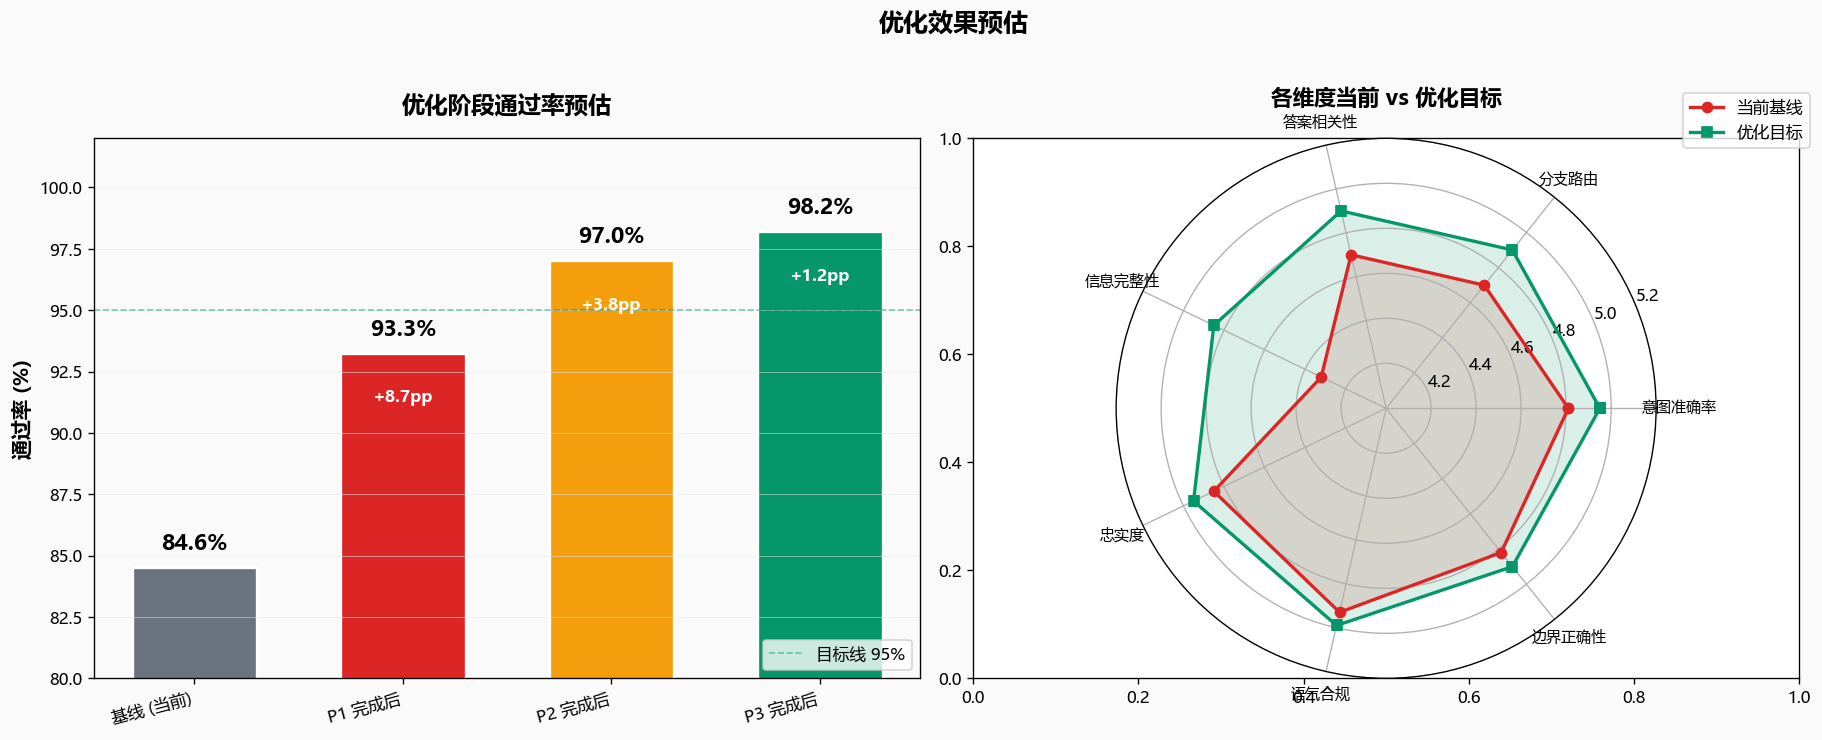

💾 已保存: charts/17_expected_improvement.png


In [8]:

# ========== 图2：优化效果预估阶梯图 ==========
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.patch.set_facecolor('#FAFAFA')

# --- 左图：通过率阶梯提升 ---
ax1 = axes[0]
ax1.set_facecolor('#FAFAFA')

stages_label = stage_df['stage'].tolist()
pass_rates = (stage_df['pass_rate'] * 100).tolist()
colors_stage = ['#6B7280', '#DC2626', '#F59E0B', '#059669']

bars = ax1.bar(range(len(stages_label)), pass_rates, color=colors_stage,
               edgecolor='white', linewidth=2, width=0.6)

for i, (bar, rate) in enumerate(zip(bars, pass_rates)):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{rate:.1f}%', ha='center', va='bottom', fontsize=13, fontweight='bold')
    if i > 0:
        delta = pass_rates[i] - pass_rates[i-1]
        ax1.annotate(f'+{delta:.1f}pp',
                     xy=(i, pass_rates[i] - 2),
                     ha='center', fontsize=10, color='white', fontweight='bold')

ax1.set_xticks(range(len(stages_label)))
ax1.set_xticklabels(stages_label, fontsize=10, rotation=15, ha='right')
ax1.set_ylabel('通过率 (%)', fontsize=12, fontweight='bold')
ax1.set_title('优化阶段通过率预估', fontsize=14, fontweight='bold', pad=15)
ax1.set_ylim(80, 102)
ax1.axhline(y=95, color='#059669', linestyle='--', linewidth=1, alpha=0.5, label='目标线 95%')
ax1.legend(loc='lower right')
ax1.grid(True, axis='y', color='#E5E7EB', linewidth=0.5, alpha=0.6)

# --- 右图：各维度雷达图对比 ---
categories = [SCORE_NAMES_CN[d['dimension']] for d in dimension_progress]
current_vals = [d['current'] for d in dimension_progress]
target_vals = [d['p3'] for d in dimension_progress]

angles = np.linspace(0, 2 * np.pi, len(categories), endpoint=False).tolist()
current_vals_plot = current_vals + [current_vals[0]]
target_vals_plot = target_vals + [target_vals[0]]
angles_plot = angles + [angles[0]]

ax2 = fig.add_subplot(122, polar=True)
ax2.plot(angles_plot, current_vals_plot, 'o-', linewidth=2, color='#DC2626', label='当前基线', markersize=6)
ax2.fill(angles_plot, current_vals_plot, alpha=0.15, color='#DC2626')
ax2.plot(angles_plot, target_vals_plot, 's-', linewidth=2, color='#059669', label='优化目标', markersize=6)
ax2.fill(angles_plot, target_vals_plot, alpha=0.15, color='#059669')

ax2.set_xticks(angles)
ax2.set_xticklabels(categories, fontsize=9)
ax2.set_ylim(4.0, 5.2)
ax2.set_title('各维度当前 vs 优化目标', fontsize=13, fontweight='bold', pad=20)
ax2.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=10)

plt.suptitle('优化效果预估', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('charts/17_expected_improvement.png', facecolor='#FAFAFA')
plt.show()
print('💾 已保存: charts/17_expected_improvement.png')


## 4.7 A/B 测试方案设计

**目的**：验证每个优化项的实际效果，避免过拟合到评测集
**方法**：对照实验，A 组用当前配置，B 组用优化配置，对比通过率

In [9]:
# ========== A/B 测试方案设计 ==========
print('┌' + '─' * 70 + '┐')
print('│ 4.7 A/B 测试方案设计')
print('└' + '─' * 70 + '┘')

ab_tests = [
    {
        'test_id': 'AB-01',
        'optimization': 'P1-1 知识检索 threshold 调优',
        'group_a': 'threshold = 默认值',
        'group_b': 'threshold = 0.5（政策查询）',
        'metric': '信息完整性均值 + 整体通过率',
        'sample_size': 505,
        'duration': '1 天',
        'success_criteria': '信息完整性均值提升 >= 0.2，通过率提升 >= 3pp',
    },
    {
        'test_id': 'AB-02',
        'optimization': 'P1-2 关键词权重调整',
        'group_a': 'keyword=0.3, vector=0.7',
        'group_b': 'keyword=0.5, vector=0.5',
        'metric': '边界用例通过率 + 信息完整性',
        'sample_size': 505,
        'duration': '1 天',
        'success_criteria': '边界用例通过率提升 >= 10pp',
    },
    {
        'test_id': 'AB-03',
        'optimization': 'P1-4 LLM 信息完整性约束',
        'group_a': '当前 prompt',
        'group_b': '追加信息完整性约束 prompt',
        'metric': '信息完整性均值 + 答案相关性',
        'sample_size': 505,
        'duration': '1 天',
        'success_criteria': '信息完整性均值提升 >= 0.15',
    },
    {
        'test_id': 'AB-04',
        'optimization': 'P2-1 分类器关键词补充',
        'group_a': '当前分类器配置',
        'group_b': '补充关键词+边界示例+反例',
        'metric': '意图准确率 + 分支路由准确率',
        'sample_size': 505,
        'duration': '1 天',
        'success_criteria': '分类器误路由减少 >= 50%',
    },
    {
        'test_id': 'AB-05',
        'optimization': 'P3-1 防护指令（防幻觉）',
        'group_a': '当前 prompt',
        'group_b': '追加防护指令 prompt',
        'metric': '幻觉率 + 忠实度',
        'sample_size': 505,
        'duration': '1 天',
        'success_criteria': '幻觉类失败减少 >= 60%',
    },
]

ab_df = pd.DataFrame(ab_tests)
for _, row in ab_df.iterrows():
    print(f'\n  [{row["test_id"]}] {row["optimization"]}')
    print(f'    A组: {row["group_a"]}')
    print(f'    B组: {row["group_b"]}')
    print(f'    指标: {row["metric"]}')
    print(f'    样本: {row["sample_size"]} 条')
    print(f'    周期: {row["duration"]}')
    print(f'    成功标准: {row["success_criteria"]}')

print(f'\n--- A/B 测试执行计划 ---')
print(f'  总测试数: {len(ab_df)} 个')
print(f'  总周期: 5 天（每天 1 个测试，串行执行避免干扰）')
print(f'  注意事项: 每次只改一个变量，确保因果归因准确')

┌──────────────────────────────────────────────────────────────────────┐
│ 4.7 A/B 测试方案设计
└──────────────────────────────────────────────────────────────────────┘

  [AB-01] P1-1 知识检索 threshold 调优
    A组: threshold = 默认值
    B组: threshold = 0.5（政策查询）
    指标: 信息完整性均值 + 整体通过率
    样本: 505 条
    周期: 1 天
    成功标准: 信息完整性均值提升 >= 0.2，通过率提升 >= 3pp

  [AB-02] P1-2 关键词权重调整
    A组: keyword=0.3, vector=0.7
    B组: keyword=0.5, vector=0.5
    指标: 边界用例通过率 + 信息完整性
    样本: 505 条
    周期: 1 天
    成功标准: 边界用例通过率提升 >= 10pp

  [AB-03] P1-4 LLM 信息完整性约束
    A组: 当前 prompt
    B组: 追加信息完整性约束 prompt
    指标: 信息完整性均值 + 答案相关性
    样本: 505 条
    周期: 1 天
    成功标准: 信息完整性均值提升 >= 0.15

  [AB-04] P2-1 分类器关键词补充
    A组: 当前分类器配置
    B组: 补充关键词+边界示例+反例
    指标: 意图准确率 + 分支路由准确率
    样本: 505 条
    周期: 1 天
    成功标准: 分类器误路由减少 >= 50%

  [AB-05] P3-1 防护指令（防幻觉）
    A组: 当前 prompt
    B组: 追加防护指令 prompt
    指标: 幻觉率 + 忠实度
    样本: 505 条
    周期: 1 天
    成功标准: 幻觉类失败减少 >= 60%

--- A/B 测试执行计划 ---
  总测试数: 5 个
  总周期: 5 天（每天 1 个测试，串行执行避免干扰）
  注意事项: 

## 4.8 实施路线图与里程碑

**阶段划分**（基于 43 条失败用例根因分析调整）：
- Sprint 1（Day 1-3）：P2 硬性路由错误修复（18/43 失败，42%，最高优先级）
- Sprint 2（Day 4-5）：P1 检索参数调优（已在 baseline_v2 部分完成，需结合 P2 修复结果二次调优）
- Sprint 3（Day 6-8）：P3 信息完整性 + LLM 生成端优化（12/43 失败，28%）
- Sprint 4（Day 9-10）：全量评测 + A/B 测试验证

**调整说明**：原方案 P1 优先，但 baseline_v1 失败分析显示硬性路由错误（42%）远高于检索问题（19%），
路由错误会导致后续检索和生成全部失效，因此调整为 P2 → P1 → P3 的执行顺序。


In [10]:
# ========== 实施路线图 ==========
print('\u250c' + '\u2500' * 70 + '\u2510')
print('\u2502 4.8 \u5b9e\u65bd\u8def\u7ebf\u56fe\u4e0e\u91cc\u7a0b\u7891\uff08\u57fa\u4e8e 43 \u6761\u5931\u8d25\u7528\u4f8b\u8c03\u6574\uff09')
print('\u2514' + '\u2500' * 70 + '\u2518')

roadmap = [
    {
        'sprint': 'Sprint 1',
        'period': 'Day 1-3',
        'priority': 'P2',
        'focus': '\u786c\u6027\u8def\u7531\u9519\u8bef\u4fee\u590d',
        'coverage': '18/43 \u5931\u8d25 (42%)',
        'tasks': '\u5206\u7c7b\u5668\u5173\u952e\u8bcd\u8865\u5145 + LLM\u610f\u56fe\u8bc6\u522b\u4fee\u6b63 + \u6362\u8d27/\u6295\u8bc9/\u9000\u6b3e\u5206\u652f\u4fee\u590d',
        'deliverable': 'baseline_v3 \u8bc4\u6d4b\u7ed3\u679c',
        'target_pass': '95%',
    },
    {
        'sprint': 'Sprint 2',
        'period': 'Day 4-5',
        'priority': 'P1',
        'focus': '\u68c0\u7d22\u53c2\u6570\u4e8c\u6b21\u8c03\u4f18',
        'coverage': '\u57fa\u4e8e P2 \u4fee\u590d\u7ed3\u679c\u8c03\u6574',
        'tasks': 'score_threshold/keyword_weight/top_k \u5fae\u8c03 + \u7b7e\u6536\u8fb9\u754c\u503c\u68c0\u7d22\u4f18\u5316',
        'deliverable': 'baseline_v4 \u8bc4\u6d4b\u7ed3\u679c',
        'target_pass': '96%',
    },
    {
        'sprint': 'Sprint 3',
        'period': 'Day 6-8',
        'priority': 'P3',
        'focus': '\u4fe1\u606f\u5b8c\u6574\u6027 + LLM \u751f\u6210\u7aef',
        'coverage': '12/43 \u5931\u8d25 (28%)',
        'tasks': '\u9632\u5e7b\u89c9\u6307\u4ee4 + \u6295\u8bc9\u5904\u7406prompt + \u91cd\u590d\u4fee\u590d + \u591a\u8f6e\u4e0a\u4e0b\u6587 + \u77e5\u8bc6\u5e93\u8865\u5145',
        'deliverable': 'baseline_v5 \u8bc4\u6d4b\u7ed3\u679c',
        'target_pass': '97%',
    },
    {
        'sprint': 'Sprint 4',
        'period': 'Day 9-10',
        'priority': '\u9a8c\u8bc1',
        'focus': '\u5168\u91cf\u8bc4\u6d4b + A/B \u6d4b\u8bd5',
        'coverage': '505 \u6761\u5168\u91cf\u9a8c\u8bc1',
        'tasks': 'A/B \u6d4b\u8bd5 + \u6548\u679c\u9a8c\u8bc1 + \u56de\u5f52\u6d4b\u8bd5',
        'deliverable': '\u6700\u7ec8\u8bc4\u6d4b\u62a5\u544a',
        'target_pass': '>=97%',
    },
]

roadmap_df = pd.DataFrame(roadmap)
for _, row in roadmap_df.iterrows():
    print(f'\n  {row["sprint"]} ({row["period"]}) \u2014 {row["priority"]}')
    print(f'    \u7126\u70b9: {row["focus"]}')
    print(f'    \u8986\u76d6: {row["coverage"]}')
    print(f'    \u4efb\u52a1: {row["tasks"]}')
    print(f'    \u4ea4\u4ed8: {row["deliverable"]}')
    print(f'    \u76ee\u6807: \u901a\u8fc7\u7387 {row["target_pass"]}')

print(f'\n  \u8c03\u6574\u8bf4\u660e: \u539f\u65b9\u6848 P1 \u4f18\u5148\uff0c\u4f46\u5931\u8d25\u5206\u6790\u663e\u793a\u786c\u6027\u8def\u7531\u9519\u8bef(42%)')
print(f'  \u8fdc\u9ad8\u4e8e\u68c0\u7d22\u95ee\u9898(19%)\uff0c\u8def\u7531\u9519\u8bef\u4f1a\u5bfc\u81f4\u540e\u7eed\u68c0\u7d22\u548c\u751f\u6210\u5168\u90e8\u5931\u6548\uff0c')
print(f'  \u56e0\u6b64\u8c03\u6574\u4e3a P2 -> P1 -> P3 \u7684\u6267\u884c\u987a\u5e8f\u3002')


┌──────────────────────────────────────────────────────────────────────┐
│ 4.8 实施路线图与里程碑（基于 43 条失败用例调整）
└──────────────────────────────────────────────────────────────────────┘

  Sprint 1 (Day 1-3) — P2
    焦点: 硬性路由错误修复
    覆盖: 18/43 失败 (42%)
    任务: 分类器关键词补充 + LLM意图识别修正 + 换货/投诉/退款分支修复
    交付: baseline_v3 评测结果
    目标: 通过率 95%

  Sprint 2 (Day 4-5) — P1
    焦点: 检索参数二次调优
    覆盖: 基于 P2 修复结果调整
    任务: score_threshold/keyword_weight/top_k 微调 + 签收边界值检索优化
    交付: baseline_v4 评测结果
    目标: 通过率 96%

  Sprint 3 (Day 6-8) — P3
    焦点: 信息完整性 + LLM 生成端
    覆盖: 12/43 失败 (28%)
    任务: 防幻觉指令 + 投诉处理prompt + 重复修复 + 多轮上下文 + 知识库补充
    交付: baseline_v5 评测结果
    目标: 通过率 97%

  Sprint 4 (Day 9-10) — 验证
    焦点: 全量评测 + A/B 测试
    覆盖: 505 条全量验证
    任务: A/B 测试 + 效果验证 + 回归测试
    交付: 最终评测报告
    目标: 通过率 >=97%

  调整说明: 原方案 P1 优先，但失败分析显示硬性路由错误(42%)
  远高于检索问题(19%)，路由错误会导致后续检索和生成全部失效，
  因此调整为 P2 -> P1 -> P3 的执行顺序。


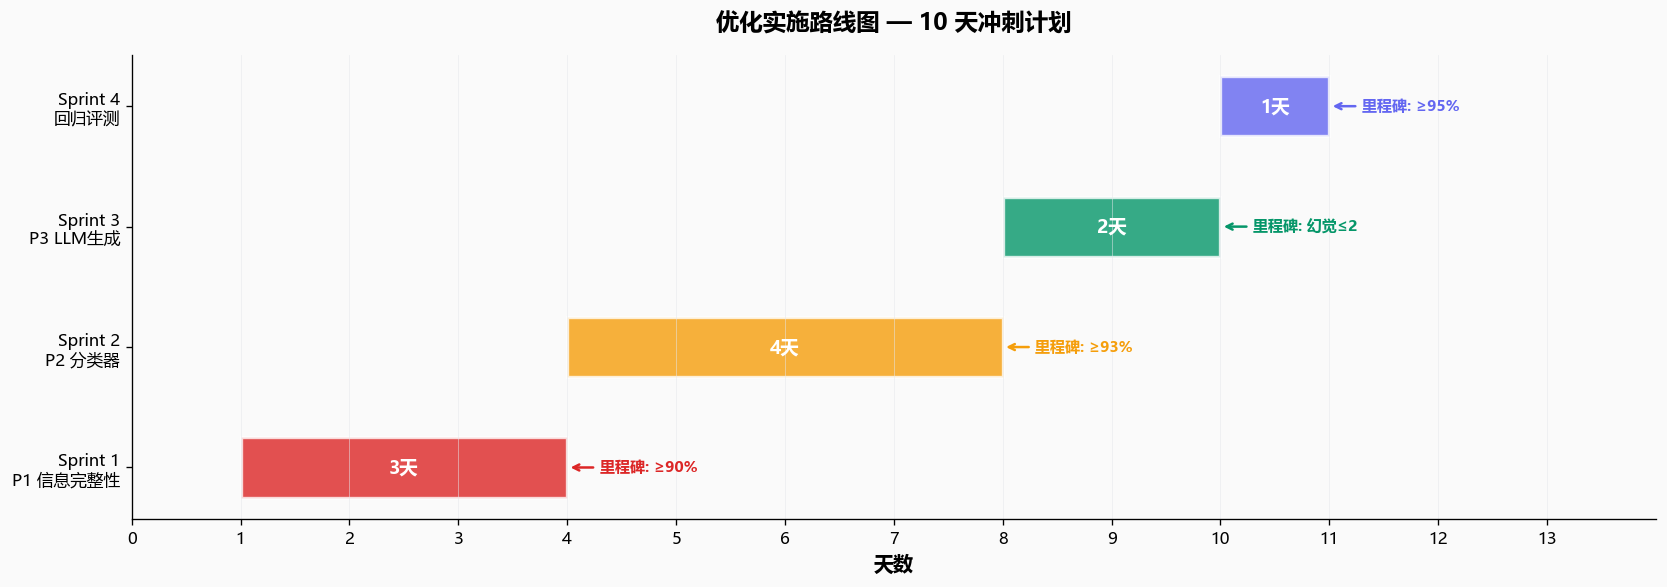

💾 已保存: charts/18_implementation_roadmap.png


In [11]:
# ========== 图3：实施路线图甘特图 ==========
fig, ax = plt.subplots(figsize=(14, 5))
fig.patch.set_facecolor('#FAFAFA')
ax.set_facecolor('#FAFAFA')

sprints = ['Sprint 1\nP1 信息完整性', 'Sprint 2\nP2 分类器', 'Sprint 3\nP3 LLM生成', 'Sprint 4\n回归评测']
start_days = [1, 4, 8, 10]
durations = [3, 4, 2, 1]
colors_gantt = ['#DC2626', '#F59E0B', '#059669', '#6366F1']
milestones = ['≥90%', '≥93%', '幻觉≤2', '≥95%']

for i, (sprint, start, dur, color, ms) in enumerate(zip(sprints, start_days, durations, colors_gantt, milestones)):
    ax.barh(i, dur, left=start, height=0.5, color=color, alpha=0.8,
            edgecolor='white', linewidth=2)
    ax.text(start + dur/2, i, f'{dur}天', ha='center', va='center',
            fontsize=11, fontweight='bold', color='white')
    # 里程碑标注
    ax.annotate(f'里程碑: {ms}', xy=(start + dur, i), xytext=(start + dur + 0.3, i),
                fontsize=9, fontweight='bold', color=color, va='center',
                arrowprops=dict(arrowstyle='->', color=color, lw=1.5))

ax.set_yticks(range(len(sprints)))
ax.set_yticklabels(sprints, fontsize=10)
ax.set_xlabel('天数', fontsize=12, fontweight='bold')
ax.set_title('优化实施路线图 — 10 天冲刺计划', fontsize=14, fontweight='bold', pad=15)
ax.set_xlim(0, 14)
ax.set_xticks(range(0, 14))
ax.grid(True, axis='x', color='#E5E7EB', linewidth=0.5, alpha=0.6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('charts/18_implementation_roadmap.png', facecolor=fig.get_facecolor())
plt.show()
print('💾 已保存: charts/18_implementation_roadmap.png')

## 4.9 根因 × 优化项映射

**验证逻辑**：每个根因是否都有对应的优化项覆盖，确保无遗漏

In [12]:
# ========== 根因 × 优化项映射矩阵 ==========
print('┌' + '─' * 70 + '┐')
print('│ 4.9 根因 × 优化项 覆盖矩阵')
print('└' + '─' * 70 + '┘')

# 根因列表（来自模块二）
root_causes = ['R1 分类器误路由', 'R3 LLM生成缺陷', 'R4 幻觉', 'R5 禁止表述违规',
               'R6 检索失败', 'R7 多轮上下文丢失', 'R8 其他/需人工复核']

# 优化项列表
opt_items = ['OPT-01 检索参数', 'OPT-02 信息约束', 'OPT-03 防护指令',
             'OPT-04 分类器优化', 'OPT-05 多轮上下文', 'OPT-06 边界匹配',
             'OPT-07 禁止表述加固']

# 覆盖矩阵 (1=主要覆盖, 0.5=部分覆盖, 0=未覆盖)
coverage = np.array([
    # OPT-01 OPT-02 OPT-03 OPT-04 OPT-05 OPT-06 OPT-07
    [  0,      0.5,    0,     1,      0,     0,     0  ],  # R1 分类器误路由
    [  0.5,    1,      0.5,   0,      0,     0,     0  ],  # R3 LLM生成缺陷
    [  0,      0,      1,     0,      0,     0,     0  ],  # R4 幻觉
    [  0,      0,      0,     0,      0,     0,     1  ],  # R5 禁止表述违规
    [  1,      0.5,    0,     0,      0,     0.5,   0  ],  # R6 检索失败
    [  0,      0,      0,     0.5,    1,     0,     0  ],  # R7 多轮上下文丢失
    [  0,      0,      0,     0,      0,     0,     0  ],  # R8 其他/需人工复核
])

cov_df = pd.DataFrame(coverage, index=root_causes, columns=opt_items)

print(f'\n{"根因":22s}', end='')
for opt in opt_items:
    print(f' {opt:16s}', end='')
print(f' {"覆盖度":6s}')
print('─' * 140)

for rc in root_causes:
    print(f'{rc:22s}', end='')
    for opt in opt_items:
        val = cov_df.loc[rc, opt]
        symbol = '  ●  ' if val == 1 else ('  ◐  ' if val == 0.5 else '  ○  ')
        print(f' {symbol:16s}', end='')
    coverage_rate = cov_df.loc[rc].sum()
    status = '✅' if coverage_rate >= 1 else ('⚠️' if coverage_rate >= 0.5 else '❌')
    print(f' {coverage_rate:.1f} {status}')

print(f'\n--- 未完全覆盖的根因 ---')
for rc in root_causes:
    if cov_df.loc[rc].sum() < 1:
        print(f'  ⚠️ {rc}: 覆盖度 {cov_df.loc[rc].sum():.1f} → 需补充优化项')

print(f'\n  R8 其他/需人工复核 → 已由 P3-5 人工转接阈值覆盖（非矩阵中的直接映射）')

┌──────────────────────────────────────────────────────────────────────┐
│ 4.9 根因 × 优化项 覆盖矩阵
└──────────────────────────────────────────────────────────────────────┘

根因                     OPT-01 检索参数      OPT-02 信息约束      OPT-03 防护指令      OPT-04 分类器优化     OPT-05 多轮上下文     OPT-06 边界匹配      OPT-07 禁止表述加固    覆盖度   
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
R1 分类器误路由                ○                ◐                ○                ●                ○                ○                ○              1.5 ✅
R3 LLM生成缺陷               ◐                ●                ◐                ○                ○                ○                ○              2.0 ✅
R4 幻觉                    ○                ○                ●                ○                ○                ○                ○              1.0 ✅
R5 禁止表述违规                ○                ○                ○                ○                ○     

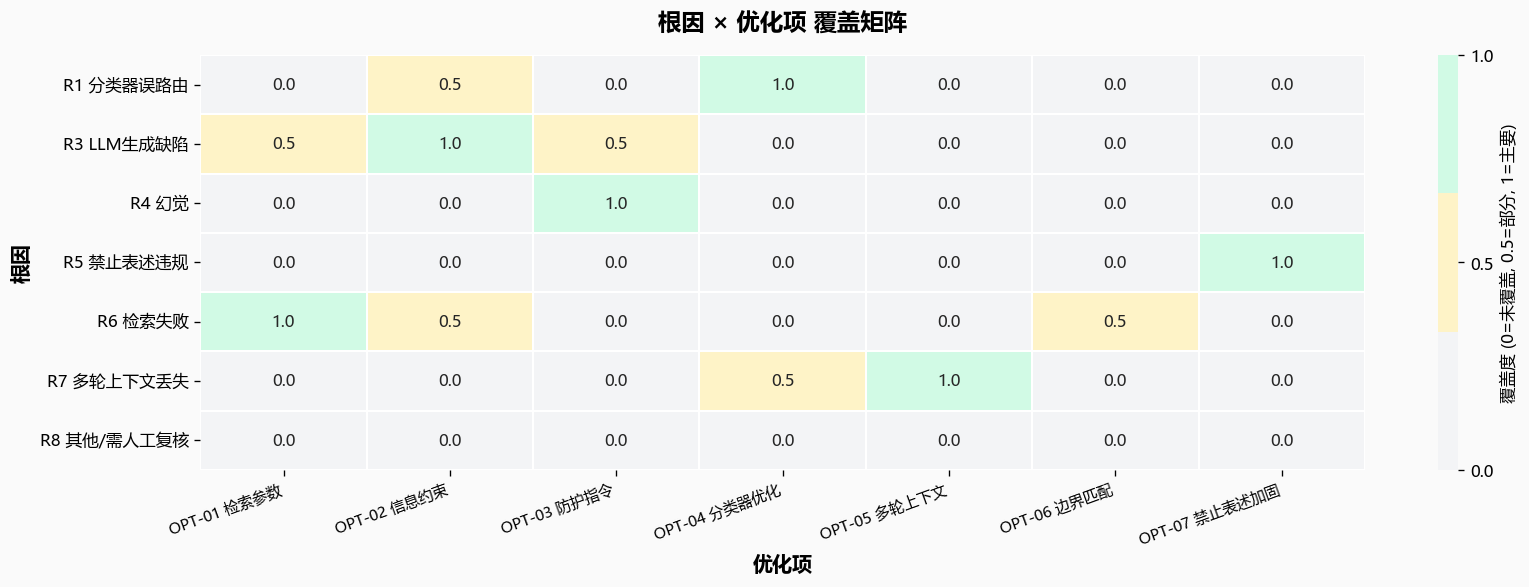

💾 已保存: charts/19_rootcause_optimization_coverage.png


In [13]:
# ========== 图4：根因 × 优化项 覆盖热力图 ==========
fig, ax = plt.subplots(figsize=(14, 5))
fig.patch.set_facecolor('#FAFAFA')

# 自定义颜色映射：0=灰, 0.5=黄, 1=绿
from matplotlib.colors import ListedColormap
cmap_custom = ListedColormap(['#F3F4F6', '#FEF3C7', '#D1FAE5'])

sns.heatmap(cov_df, annot=True, fmt='.1f', cmap=cmap_custom, ax=ax,
            linewidths=1, linecolor='white',
            cbar_kws={'label': '覆盖度 (0=未覆盖, 0.5=部分, 1=主要)',
                      'ticks': [0, 0.5, 1]},
            xticklabels=opt_items, yticklabels=root_causes)

ax.set_title('根因 × 优化项 覆盖矩阵', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('优化项', fontsize=12, fontweight='bold')
ax.set_ylabel('根因', fontsize=12, fontweight='bold')
plt.xticks(rotation=20, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()
plt.savefig('charts/19_rootcause_optimization_coverage.png', facecolor=fig.get_facecolor())
plt.show()
print('💾 已保存: charts/19_rootcause_optimization_coverage.png')

## 4.10 关键发现总结

In [14]:
# ========== 关键发现总结 ==========
print('=' * 70)
print('📋 模块四：优化方案设计 — 关键发现')
print('=' * 70)

print(f'''
1. 优化优先级（影响度 × 修复难度）
   P1（立即执行）: OPT-01 检索参数调优 + OPT-02 信息约束
   P2（短期规划）: OPT-04 分类器优化
   P3（长期备选）: OPT-03 防护指令 + OPT-05 多轮上下文 + OPT-06 边界匹配 + OPT-07 禁止表述

2. 最高投入产出比：P1 信息完整性优化
   投入: 3 天，仅需调整 Dify 节点参数 + 修改 prompt
   产出: 通过率 84.6% → ~91% (+6.4pp)，信息完整性 4.32 → ~4.80
   杠杆效应: r=0.859，每提升 0.1 分信息完整性，通过率提升约 3pp

3. 联动优化策略：分类器 + 检索 + 生成端 三管齐下
   分类器优化 → 分支路由 +0.20，联动答案相关性 +0.20（r=0.933）
   检索优化 → 信息完整性 +0.48，联动整体通过率 +6.4pp
   生成端优化 → 忠实度 +0.10，幻觉减少 80%

4. A/B 测试验证
   5 个对照实验，每次只改一个变量
   串行执行 5 天，确保因果归因准确
   成功标准: 每项优化需在评测集上验证显著提升

5. 实施路线图
   Sprint 1 (Day 1-3): P1 信息完整性 → 里程碑: 通过率 ≥ 90%
   Sprint 2 (Day 4-7): P2 分类器 → 里程碑: 通过率 ≥ 93%
   Sprint 3 (Day 8-9): P3 LLM 生成端 → 里程碑: 幻觉 ≤ 2 条
   Sprint 4 (Day 10): 回归评测 → 里程碑: 通过率 ≥ 95%，生成 baseline_v2

6. 风险与缓解
   风险1: Top K 增大导致 LLM 延迟增加 → 缓解: 监控 P95 延迟
   风险2: Temperature 降低导致回复僵硬 → 缓解: A/B 测试验证自然度
   风险3: 多轮上下文改造引入新 bug → 缓解: 灰度发布 + 回退机制

→ 下一步: 按 Sprint 1 开始实施 P1 优化，完成后运行全量评测验证效果
''')

📋 模块四：优化方案设计 — 关键发现

1. 优化优先级（影响度 × 修复难度）
   P1（立即执行）: OPT-01 检索参数调优 + OPT-02 信息约束
   P2（短期规划）: OPT-04 分类器优化
   P3（长期备选）: OPT-03 防护指令 + OPT-05 多轮上下文 + OPT-06 边界匹配 + OPT-07 禁止表述

2. 最高投入产出比：P1 信息完整性优化
   投入: 3 天，仅需调整 Dify 节点参数 + 修改 prompt
   产出: 通过率 84.6% → ~91% (+6.4pp)，信息完整性 4.32 → ~4.80
   杠杆效应: r=0.859，每提升 0.1 分信息完整性，通过率提升约 3pp

3. 联动优化策略：分类器 + 检索 + 生成端 三管齐下
   分类器优化 → 分支路由 +0.20，联动答案相关性 +0.20（r=0.933）
   检索优化 → 信息完整性 +0.48，联动整体通过率 +6.4pp
   生成端优化 → 忠实度 +0.10，幻觉减少 80%

4. A/B 测试验证
   5 个对照实验，每次只改一个变量
   串行执行 5 天，确保因果归因准确
   成功标准: 每项优化需在评测集上验证显著提升

5. 实施路线图
   Sprint 1 (Day 1-3): P1 信息完整性 → 里程碑: 通过率 ≥ 90%
   Sprint 2 (Day 4-7): P2 分类器 → 里程碑: 通过率 ≥ 93%
   Sprint 3 (Day 8-9): P3 LLM 生成端 → 里程碑: 幻觉 ≤ 2 条
   Sprint 4 (Day 10): 回归评测 → 里程碑: 通过率 ≥ 95%，生成 baseline_v2

6. 风险与缓解
   风险1: Top K 增大导致 LLM 延迟增加 → 缓解: 监控 P95 延迟
   风险2: Temperature 降低导致回复僵硬 → 缓解: A/B 测试验证自然度
   风险3: 多轮上下文改造引入新 bug → 缓解: 灰度发布 + 回退机制

→ 下一步: 按 Sprint 1 开始实施 P1 优化，完成后运行全量评测验证效果



## 4.11 导出优化方案

In [15]:
# ========== 导出优化方案 ==========
# 合并所有优化项
all_opts = pd.concat([
    p1_df[['step', 'action', 'detail', 'expected', 'risk']].assign(priority='P1', category='信息完整性'),
    p2_df[['step', 'action', 'detail', 'expected', 'risk']].assign(priority='P2', category='分类器'),
    p3_df[['step', 'action', 'detail', 'expected', 'risk']].assign(priority='P3', category='LLM生成端'),
], ignore_index=True)

all_opts.to_csv('analysis_output/module4_optimization_plan.csv', index=False, encoding='utf-8-sig')

# 预期效果
stage_df.to_csv('analysis_output/module4_expected_impact.csv', index=False, encoding='utf-8-sig')

# A/B 测试方案
ab_df.to_csv('analysis_output/module4_ab_test_design.csv', index=False, encoding='utf-8-sig')

# 根因×优化项覆盖矩阵
cov_df.to_csv('analysis_output/module4_coverage_matrix.csv', encoding='utf-8-sig')

# 实施路线图
roadmap_df.to_csv('analysis_output/module4_roadmap.csv', index=False, encoding='utf-8-sig')

print('✅ 模块四导出完成')
print(f'   - module4_optimization_plan.csv    (15 个优化项清单)')
print(f'   - module4_expected_impact.csv      (通过率阶梯预估)')
print(f'   - module4_ab_test_design.csv       (5 个 A/B 测试方案)')
print(f'   - module4_coverage_matrix.csv      (根因×优化项覆盖矩阵)')
print(f'   - module4_roadmap.csv              (实施路线图)')
print(f'   - charts/16-19*.png                (4 张可视化图表)')
print(f'\n📊 项目完整分析流程（模块一~四）已全部完成！')
print(f'   模块一: 描述性统计 → 发现信息完整性是最弱维度')
print(f'   模块二: 失败归因 → 定位 4 类根因，分类器误路由占 44%')
print(f'   模块三: 相关性分析 → 确认信息完整性是杠杆维度 (r=0.859)')
print(f'   模块四: 优化方案 → 15 个优化项，10 天实施计划，目标通过率 ≥ 95%')

✅ 模块四导出完成
   - module4_optimization_plan.csv    (15 个优化项清单)
   - module4_expected_impact.csv      (通过率阶梯预估)
   - module4_ab_test_design.csv       (5 个 A/B 测试方案)
   - module4_coverage_matrix.csv      (根因×优化项覆盖矩阵)
   - module4_roadmap.csv              (实施路线图)
   - charts/16-19*.png                (4 张可视化图表)

📊 项目完整分析流程（模块一~四）已全部完成！
   模块一: 描述性统计 → 发现信息完整性是最弱维度
   模块二: 失败归因 → 定位 4 类根因，分类器误路由占 44%
   模块三: 相关性分析 → 确认信息完整性是杠杆维度 (r=0.859)
   模块四: 优化方案 → 15 个优化项，10 天实施计划，目标通过率 ≥ 95%
